# Análise exploratória da base de churn

**Disciplina:** Sistemas Inteligentes — CIn/UFPE  
**Etapa atual:** EDA concluída (Partes 1–9), com consolidação temporal exploratória e decisões de pré-processamento documentadas.

Este notebook registra a investigação da base disponibilizada no miniprojeto.
As derivações ficam em visões auxiliares. A base original é preservada; pré-processamento definitivo e modelos permanecem fora desta entrega.


## 1. Introdução e contextualização

### 1.1. Objetivo da análise

A operadora de telecomunicações deseja antecipar quais clientes poderão cancelar
seus serviços **nos 60 dias seguintes à data de corte**, para priorizar ações
preventivas de retenção. A EDA deve verificar se os dados permitem representar
corretamente os clientes no momento dessa decisão e observar seu resultado futuro.

No aprendizado supervisionado, o problema é de **classificação binária**:
`churn = 1` indica cancelamento nesse horizonte; `churn = 0` indica permanência
durante a mesma janela. Esta definição pressupõe clientes elegíveis no corte
e acompanhamento suficiente para conhecer o desfecho dos 60 dias.

O recall será relevante para reduzir cancelamentos não identificados, mas a
avaliação futura também deverá considerar falsos positivos, custo das ações e
capacidade da equipe de retenção. Não calculamos métricas nem treinamos modelos aqui.

### 1.2. Base de dados e problema de churn

O arquivo `base_churn_5000_VF2_aluno.xlsx - Dados_Sinteticos_VF2.csv` é um **CSV**,
apesar de conter `.xlsx` no nome. Usa UTF-8, campos separados por vírgulas,
vírgula decimal na mensalidade e aspas em campos com vírgulas internas.

As definições de negócio das Aulas 1 e 2 foram fornecidas no alinhamento do projeto.
No arquivo real, há identificação, aquisição, mensalidade, datas de chamados,
faturas em atraso, contrato, pagamento, indicadores de serviço e data de churn.
Não há `data_corte`, `churn`, `tempo_cliente_meses` ou `chamados_suporte` prontos.
A orientação principal são as Aulas 1 e 2 do professor Germano Vasconcelos,
conforme as definições fornecidas no projeto: corte em **21/09/2026**, horizonte
de **60 dias** e observação em **21/11/2026**. Os PDFs não estão no workspace;
as regras aqui adotadas são as explicitadas pelo usuário, sem copiar rótulos
de exemplos didáticos. O usuário confirmou acompanhamento completo de todos os
clientes elegíveis até 21/11/2026, inclusive daqueles sem data de churn. Essa
garantia é uma regra do exercício, não uma informação inferida de campos vazios.

### 1.3. Relação com as próximas etapas do projeto

**Hipóteses de negócio investigadas nas partes seguintes:**

- A taxa de churn difere conforme tempo de permanência, mensalidade ou faturas em atraso?
- A quantidade de chamados nos 90 dias anteriores ao corte está associada ao cancelamento?
- Contrato, forma de pagamento, fibra óptica e débito automático distinguem taxas de churn?
- Existe desbalanceamento entre as classes do alvo corretamente definido?

Essas perguntas não são achados. Associação não demonstrará causalidade.
A EDA orientará um pré-processamento modular e reproduzível para futuros
classificadores, incluindo Árvores de Decisão, e para a investigação de perfis
por métodos não supervisionados. Nesta etapa, preservamos a base e não aplicamos tratamentos.


### 1.4. Organização da EDA

| Parte | Conteúdo e justificativa | Situação |
|---|---|---|
| 1. Introdução e contextualização | Apresentar o problema, os objetivos e os limites da análise. | Implementada |
| 2. Carregamento e compreensão inicial | Ler a base, observar dimensões, exemplos, tipos e estatísticas iniciais. | Implementada |
| 3. Qualidade e consistência dos dados | Investigar ausências, repetições, categorias, domínios e coerência das datas; distinguir ausência de informação de ausência de evento, sem corrigir registros. | Implementada |
| 4. Análise univariada | Examinar distribuições numéricas e frequências categóricas; investigar valores extremos com gráficos e resumos justificados, sem removê-los. | Implementada |
| 5. Compreensão da variável-alvo | Aplicar o corte, a elegibilidade e a cobertura futura confirmada antes de analisar o alvo e examinar o equilíbrio das classes. | Implementada |
| 6. Análise bivariada | Comparar atributos numéricos e categóricos com o churn, considerando o tamanho dos grupos e sem interpretar associação como causa. | Implementada |
| 7. Correlações entre atributos | Investigar associações numéricas e possível redundância, respeitando o significado de indicadores e contagens. | Implementada |
| 8. Investigações complementares | Investigar hipóteses justificadas pelas evidências, com permanência no corte e chamados dos 90 dias anteriores, quando houver cobertura temporal suficiente. | Implementada |
| 9. Síntese e encaminhamentos | Consolidar achados, limitações e recomendações para o pré-processamento futuro. | Implementada |





## 2. Carregamento e compreensão inicial

### 2.1. Bibliotecas e configuração

Utilizamos Pandas para leitura e tabelas, NumPy para apoio numérico, e Matplotlib
e Seaborn para as visualizações das próximas partes. Aqui, tabelas são suficientes
para a inspeção inicial. As configurações abaixo alteram apenas a apresentação.

Execute as células na ordem apresentada, com o interpretador `.venv/bin/python`
e o diretório de trabalho na pasta deste notebook.


In [73]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titlesize": 13})

print("Notebook funcionando!")
print(f"Pandas: {pd.__version__} | NumPy: {np.__version__}")


Notebook funcionando!
Pandas: 2.3.3 | NumPy: 2.2.6


### 2.2. Leitura do arquivo original

`read_csv` respeita as aspas dos campos com vírgulas internas e utiliza
`decimal=","` para interpretar corretamente os valores monetários. Isso é uma
configuração de leitura, sem alterar ou regravar o arquivo.

As datas permanecem em sua representação textual. Em particular, `data_chamado`
pode reunir várias datas em uma única célula, portanto não deve ser interpretada
como uma data única. Nenhuma conversão temporal ou limpeza será realizada agora.
Campos vazios são representados pelo Pandas como `NaN`; seu significado será
investigado na etapa de qualidade.


In [74]:
caminho_base = Path("base_churn_5000_VF2_aluno.xlsx - Dados_Sinteticos_VF2.csv")

if not caminho_base.is_file():
    raise FileNotFoundError(
        "Arquivo não encontrado. Execute o notebook na pasta que contém o CSV original."
    )

df = pd.read_csv(
    caminho_base,
    sep=",",
    decimal=",",
    encoding="utf-8",
    quotechar='"',
)

print(f"Arquivo carregado: {caminho_base.name}")


Arquivo carregado: base_churn_5000_VF2_aluno.xlsx - Dados_Sinteticos_VF2.csv


### 2.3. Dimensões da base

Cada linha é um registro e cada coluna é um atributo. A contagem de linhas
não equivale necessariamente à de clientes distintos; a unicidade será examinada
na Parte 3.


In [75]:
n_linhas, n_colunas = df.shape
print(f"Quantidade de linhas: {n_linhas:,}".replace(",", "."))
print(f"Quantidade de colunas: {n_colunas}")


Quantidade de linhas: 5.020
Quantidade de colunas: 10


### 2.4. Primeiras e últimas observações

As cinco primeiras e as cinco últimas linhas ajudam a reconhecer a organização
dos registros e exemplos dos valores armazenados. Esses recortes não são uma
amostra aleatória e não representam, por si só, a distribuição da base.


In [76]:
print("Primeiras cinco observações:")
display(df.head())

print("Últimas cinco observações:")
display(df.tail())


Primeiras cinco observações:


,id_cliente,data_aquisicao_cliente,mensalidade_rs,data_chamado,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,data_ocorrencia_churn
0,C0001,21/04/2024,67.96,"09/09/2026, 15/08/2026",0.0,Bienal,Boleto,0,0,NaN
1,C0002,21/02/2025,65.95,NaN,0.0,Mensal,Cartão,0,0,NaN
2,C0003,21/03/2025,100.88,28/08/2026,1.0,Anual,Boleto,1,1,NaN
3,C0004,21/03/2025,94.80,"06/08/2026, 28/07/2026",2.0,Mensal,Cartão,0,1,NaN
4,C0005,21/02/2022,53.68,05/07/2026,2.0,Anual,Pix,0,0,NaN


Últimas cinco observações:


,id_cliente,data_aquisicao_cliente,mensalidade_rs,data_chamado,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,data_ocorrencia_churn
5015,C3618,21/02/2024,85.79,10/07/2026,1.0,Mensal,Cartão,1,1,NaN
5016,C1643,21/11/2025,57.48,"14/08/2026, 14/07/2026, 01/07/2026",2.0,Anual,Boleto,0,0,NaN
5017,C3711,21/09/2025,97.06,19/09/2026,1.0,Anual,Pix,1,0,NaN
5018,C1235,21/01/2024,111.10,"18/08/2026, 08/07/2026",2.0,Mensal,Pix,1,0,20/11/2026
5019,C4645,21/07/2025,62.15,"11/07/2026, 27/06/2026",0.0,Bienal,Boleto,0,0,NaN


### 2.5. Colunas, tipos e significado de negócio

O inventário abaixo respeita os nomes do CSV. `mensalidade_rs` é o valor mensal
cobrado, `atrasos_6m` conta faturas em atraso nos seis meses anteriores à referência
do dado, e os indicadores representam uso de fibra óptica e débito automático.
Conforme a premissa didática, mensalidade, contrato, pagamento, atrasos e indicadores
representam a fotografia em 21/09/2026. O CSV não contém histórico de atualização
para comprovar independentemente essa disponibilidade; a origem precisa documentá-la
no pré-processamento futuro.
`tipo_contrato` descreve a modalidade contratual, não o tempo já permanecido na operadora.

As definições das aulas têm estas correspondências com o arquivo:

| Conceito das aulas | Situação no CSV | Condição para uso futuro |
|---|---|---|
| `tempo_cliente_meses` | Não existe; há `data_aquisicao_cliente`. | Calcular permanência até o corte, após validar aquisição e convenção de meses. |
| `chamados_suporte` | Não existe; `data_chamado` reúne datas de eventos. | Contar somente chamados dos 90 dias anteriores ao corte e confirmar cobertura do histórico. |
| `debito_auto` | O nome presente é `debito_automatico`. | Respeitar o nome original; a definição é de indicador binário de utilização. |
| `churn` e `data_corte` | Não existem; há `data_ocorrencia_churn`. | Aplicar o corte de 21/09/2026 e usar o acompanhamento completo até 21/11/2026, confirmado para todos os elegíveis. |

Tipos de armazenamento não substituem significados: indicadores inteiros são
categóricos e datas continuam como texto. Os atributos são derivados apenas na visão auxiliar da seção 3.6.


In [77]:
descricoes_atributos = {
    "id_cliente": ("Identificador", "Código do cliente; não representa ordem ou grandeza de consumo."),
    "data_aquisicao_cliente": ("Temporal (texto)", "Início do vínculo; referência para calcular permanência até o corte."),
    "mensalidade_rs": ("Numérico contínuo", "Valor mensal cobrado pelo serviço, em reais."),
    "data_chamado": ("Temporal multivalorado (texto)", "Datas de chamados; não é ainda a contagem nos 90 dias anteriores ao corte."),
    "atrasos_6m": ("Numérico discreto", "Número de faturas em atraso nos últimos seis meses."),
    "tipo_contrato": ("Categórico nominal", "Modalidade do contrato."),
    "forma_pagamento": ("Categórico nominal", "Forma de pagamento registrada."),
    "fibra_optica": ("Categórico binário", "Indicador de fibra óptica, com valores 0 e 1 observados."),
    "debito_automatico": ("Categórico binário", "Indicador de utilização de débito automático, com valores 0 e 1 observados."),
    "data_ocorrencia_churn": ("Temporal / origem do possível alvo", "Data do cancelamento; origem para o alvo no horizonte de 60 dias após o corte."),
}

inventario = pd.DataFrame([
    {
        "Atributo": coluna,
        "Tipo no Pandas": str(df[coluna].dtype),
        "Natureza preliminar": descricoes_atributos[coluna][0],
        "Descrição preliminar": descricoes_atributos[coluna][1],
    }
    for coluna in df.columns
])

display(inventario)


,Atributo,Tipo no Pandas,Natureza preliminar,Descrição preliminar
0,id_cliente,object,Identificador,Código do cliente; não representa ordem ou gra...
1,data_aquisicao_cliente,object,Temporal (texto),Início do vínculo; referência para calcular pe...
2,mensalidade_rs,float64,Numérico contínuo,"Valor mensal cobrado pelo serviço, em reais."
3,data_chamado,object,Temporal multivalorado (texto),Datas de chamados; não é ainda a contagem nos ...
4,atrasos_6m,float64,Numérico discreto,Número de faturas em atraso nos últimos seis m...
5,tipo_contrato,object,Categórico nominal,Modalidade do contrato.
6,forma_pagamento,object,Categórico nominal,Forma de pagamento registrada.
7,fibra_optica,int64,Categórico binário,"Indicador de fibra óptica, com valores 0 e 1 o..."
8,debito_automatico,int64,Categórico binário,"Indicador de utilização de débito automático, ..."
9,data_ocorrencia_churn,object,Temporal / origem do possível alvo,Data do cancelamento; origem para o alvo no ho...


### 2.6. Grupos preliminares de atributos

Primeiro, identificamos os campos com armazenamento numérico. Depois, separamos
os grupos pelo significado dos atributos. `atrasos_6m` representa uma contagem,
embora tenha sido lida como `float64`; nenhuma conversão é feita nesta etapa.

Esta classificação serve para organizar a EDA, sem selecionar definitivamente
variáveis de entrada para modelos ou modificar os tipos do DataFrame.


In [78]:
colunas_numericas_armazenadas = df.select_dtypes(include=np.number).columns.tolist()
atributos_numericos = ["mensalidade_rs", "atrasos_6m"]
atributos_categoricos_nominais = ["tipo_contrato", "forma_pagamento"]
atributos_binarios = ["fibra_optica", "debito_automatico"]
atributos_categoricos = atributos_categoricos_nominais + atributos_binarios
atributos_temporais = ["data_aquisicao_cliente", "data_chamado", "data_ocorrencia_churn"]
atributo_identificador = "id_cliente"
coluna_origem_alvo = "data_ocorrencia_churn"

print("Armazenamento numérico:", colunas_numericas_armazenadas)
print("Quantidades numéricas:", atributos_numericos)
print("Categóricos (incluindo binários):", atributos_categoricos)
print("Temporais, ainda como texto:", atributos_temporais)
print("Identificador:", atributo_identificador)
print("Origem do possível alvo:", coluna_origem_alvo)


Armazenamento numérico: ['mensalidade_rs', 'atrasos_6m', 'fibra_optica', 'debito_automatico']
Quantidades numéricas: ['mensalidade_rs', 'atrasos_6m']
Categóricos (incluindo binários): ['tipo_contrato', 'forma_pagamento', 'fibra_optica', 'debito_automatico']
Temporais, ainda como texto: ['data_aquisicao_cliente', 'data_chamado', 'data_ocorrencia_churn']
Identificador: id_cliente
Origem do possível alvo: data_ocorrencia_churn


### 2.7. Estatísticas descritivas iniciais

O resumo das quantidades numéricas apresenta contagem de valores disponíveis,
média, desvio padrão, mínimo, quartis e máximo. A mediana corresponde à linha
`50%`. Os indicadores binários ficam fora desse resumo, pois sua interpretação
principal é categórica.

`describe` desconsidera valores ausentes nos cálculos. As estatísticas abaixo
descrevem os valores lidos, sem qualquer tratamento, e não constituem uma análise
de qualidade, distribuição ou outliers.


In [79]:
resumo_numerico = df[atributos_numericos].describe()
display(resumo_numerico)


,mensalidade_rs,atrasos_6m
count,4900.000,4985.000
mean,91.237,1.204
std,283.899,4.036
min,-85.000,0.000
25%,66.980,0.000
50%,85.915,1.000
75%,98.483,2.000
max,9999.000,99.000


Para os atributos categóricos textuais, o resumo informa a quantidade disponível
(`count`), o número de categorias distintas (`unique`), a categoria mais frequente
(`top`) e sua frequência (`freq`). Os rótulos são considerados exatamente como
estão no arquivo, sem padronização. Tabelas completas de frequências ficam para
a análise univariada.


In [80]:
resumo_categorico = df[atributos_categoricos_nominais].describe().T
display(resumo_categorico)


,count,unique,top,freq
tipo_contrato,4994,6,Mensal,2726
forma_pagamento,5000,6,Boleto,1953


**Achados empíricos:** a mensalidade média é aproximadamente **R$ 91,24** e a
mediana **R$ 85,92**. Para faturas em atraso (`atrasos_6m`), a média é **1,204** e
a mediana **1**. Esses valores descrevem os registros disponíveis, incluindo
duplicatas e valores ainda sem tratamento; não caracterizam isoladamente quem cancela.

Contrato e pagamento apresentam **6 rótulos distintos cada**. `Mensal` aparece em
**2.726 registros** e `Boleto` em **1.953**. São contagens de grafias originais:
não provam seis modalidades de negócio nem maior risco nesses grupos.

**Hipótese e recomendação futura:** investigar se mensalidade, atrasos e modalidades
contratuais se associam ao cancelamento, depois de resolver a representação das
categorias e definir o alvo em 60 dias. Não há comparação entre classes nesta parte.


### 2.8. Definição de negócio e origem da variável-alvo

A tarefa futura é prever cancelamento nos **60 dias após o corte**. O CSV não
contém `churn`; `data_ocorrencia_churn` é a fonte disponível para construir esse
rótulo. Os exemplos abaixo mostram datas preenchidas, sem criar classes.


In [81]:
exemplos_evento = df.loc[
    df[coluna_origem_alvo].notna(),
    [atributo_identificador, coluna_origem_alvo],
].head(3)

display(exemplos_evento)


,id_cliente,data_ocorrencia_churn
5,C0006,30/10/2026
7,C0008,12/11/2026
9,C0010,20/10/2026


Pela definição de negócio, `churn = 1` corresponde a cancelamento depois do corte
e até 60 dias após ele. `churn = 0` corresponde a permanência nessa janela, para
um cliente elegível cujo acompanhamento permite observar integralmente o período.
Uma data preenchida fora dessa janela não significa automaticamente classe positiva.

**Regra das aulas:** o corte informado é 21/09/2026; somar 60 dias resulta em
20/11/2026. O fechamento em 21/11/2026 está 61 dias após o corte e não amplia o
horizonte do alvo. O usuário confirmou acompanhamento completo de todos os
elegíveis até a observação. Portanto, ausência de cancelamento registrado permite
atribuir classe zero dentro do horizonte. A origem dessa garantia é o exercício,
e não o campo vazio isoladamente. A seção 3.6 documenta a construção do alvo.

`data_ocorrencia_churn` revela o evento futuro e deve servir à construção ou
avaliação do alvo, nunca como preditor. Chamados posteriores ao corte também não
podem entrar na contagem preditora dos 90 dias anteriores. As classes e contagens
exploratórias são construídas somente na visão auxiliar da seção 3.6.


### 2.9. Síntese da compreensão inicial e ponto de revisão

A leitura resultou em **5.020 registros e 10 atributos**. Foram identificados
dois atributos que representam quantidades, quatro categóricos (dois nominais
e dois binários), um identificador e três campos temporais, incluindo a origem
provável do alvo.

Quanto ao armazenamento, há **2 colunas `float64`, 2 `int64` e 6 `object`**.
`data_chamado` contém várias datas na mesma célula: suas contagens brutas não são
ainda o atributo de suporte dos 90 dias anteriores ao corte. Tempo de permanência
e alvo em 60 dias usam a referência temporal informada nas aulas, ausente como coluna no CSV.

A execução até aqui compreende leitura, inspeção e resumos iniciais. Não houve
escrita na base original, exclusão de registros, imputação, padronização,
codificação, normalização, criação de atributos ou treinamento de modelos.

**Continuidade:** a Parte 3 diagnostica qualidade e consolida uma fotografia
exploratória; as Partes 4–9 descrevem distribuições, alvo, associações, maturação
e decisões futuras, sem sobrescrever os dados originais.


## 3. Diagnóstico da qualidade dos dados

Esta parte aplica as quatro dimensões da Aula 2 ao problema de retenção:
**completude** (informações disponíveis), **validade** (tipos, representações e
domínios), **consistência** (coerência entre atributos) e **unicidade** (repetições
da unidade amostral). Erros nesses pontos podem comprometer tanto o perfil do
cliente no corte quanto seu rótulo de cancelamento futuro. As Partes 1 e 2 foram reexecutadas e conferidas com o CSV:
permanecem 5.020 linhas, 10 colunas e os mesmos resumos iniciais.

Conversões e agrupamentos abaixo são feitos **somente em estruturas auxiliares**,
para permitir o diagnóstico. `df` e o arquivo original não recebem correções.
Percentuais de registros usam as **5.020 linhas**, incluindo repetições, salvo
indicação explícita de outro denominador. Nenhum resultado representa uma decisão
automática de pré-processamento.

### 3.1. Identificação de valores ausentes

Além de `isna()`, fazemos uma segunda leitura do CSV inteiramente como texto,
com `keep_default_na=False`. Isso preserva campos vazios e eventuais marcadores
que a leitura padrão poderia transformar em `NaN`.

A auditoria distingue campos vazios, valores compostos apenas por espaços e
marcadores textuais usuais. O conjunto de marcadores é explícito e representa
candidatos a ausência, não um dicionário completo de todos os códigos possíveis.
Só somamos os candidatos **ainda não reconhecidos** pelo Pandas, evitando dupla contagem.


In [82]:
from hashlib import sha256

hash_base_antes = sha256(caminho_base.read_bytes()).hexdigest()
df_bruto = pd.read_csv(caminho_base, dtype=str, keep_default_na=False, encoding="utf-8")
assert df_bruto.shape == df.shape
assert df_bruto.columns.equals(df.columns)

marcadores_ausencia = {
    "na", "n/a", "n.a.", "nan", "null", "none", "missing", "-", "--", "?",
    "sem informação", "sem informacao", "não informado", "nao informado",
    "não disponível", "nao disponivel",
}
print("Marcadores pesquisados:", ", ".join(sorted(marcadores_ausencia)))

auditoria_ausencias = []
for coluna in df.columns:
    texto = df_bruto[coluna]
    texto_limpo = texto.str.strip().str.casefold()
    vazio = texto.eq("")
    apenas_espacos = texto.ne("") & texto_limpo.eq("")
    marcador = texto_limpo.isin(marcadores_ausencia)
    reconhecido = df[coluna].isna()
    adicional = (vazio | apenas_espacos | marcador) & ~reconhecido
    total = reconhecido | adicional
    auditoria_ausencias.append({
        "Atributo": coluna,
        "Ausentes Pandas": int(reconhecido.sum()),
        "Campos vazios no CSV": int(vazio.sum()),
        "Apenas espaços": int(apenas_espacos.sum()),
        "Marcadores textuais": int(marcador.sum()),
        "Candidatos adicionais": int(adicional.sum()),
        "Total diagnóstico": int(total.sum()),
        "Percentual (%)": 100 * total.mean(),
    })

tabela_ausencias = pd.DataFrame(auditoria_ausencias).sort_values(
    "Percentual (%)", ascending=False, kind="stable"
).set_index("Atributo")
display(tabela_ausencias.round(2))


Marcadores pesquisados: -, --, ?, missing, n.a., n/a, na, nan, nao disponivel, nao informado, none, null, não disponível, não informado, sem informacao, sem informação


,Ausentes Pandas,Campos vazios no CSV,Apenas espaços,Marcadores textuais,Candidatos adicionais,Total diagnóstico,Percentual (%)
Atributo,,,,,,,
data_ocorrencia_churn,3231,3231,0,0,0,3231,64.36
data_chamado,1053,1053,0,0,0,1053,20.98
mensalidade_rs,120,120,0,0,0,120,2.39
atrasos_6m,35,35,0,0,0,35,0.70
tipo_contrato,26,26,0,0,0,26,0.52
forma_pagamento,20,20,0,0,0,20,0.40
id_cliente,0,0,0,0,0,0,0.00
data_aquisicao_cliente,0,0,0,0,0,0,0.00
fibra_optica,0,0,0,0,0,0,0.00


**Achados empíricos:** há **120 vazios em mensalidade (2,39%)**, **35 em atrasos
(0,70%)**, **26 em contrato (0,52%)** e **20 em pagamento (0,40%)**. São lacunas
em características que poderão orientar a priorização de retenção. Não sabemos
se a ausência está associada ao risco de churn ou a processos de cadastro.

Os **1.053 vazios em chamados (20,98%)** são campos realmente vazios no CSV.
Pela semântica de consolidação da Aula 1 informada no projeto, representam
**ausência de chamados registrados**, com contagem zero na visão auxiliar.
Marcadores de informação ausente, datas inválidas ou histórico comprovadamente
incompleto não seriam convertidos em zero. Os **3.231 vazios em churn (64,36%)**
não seriam suficientes, sozinhos, para definir classe zero. Neste exercício,
a cobertura completa até 21/11/2026 foi confirmada e permite rotular os clientes
elegíveis sem cancelamento como zero. Essa premissa de acompanhamento futuro é distinta da semântica dos chamados.

Todos os ausentes da leitura correspondem a campos vazios no CSV. Não foram
encontrados campos apenas com espaços, os marcadores textuais pesquisados ou
candidatos adicionais. A tabela é suficiente para comparar a completude.
**Recomendação futura:** esclarecer a origem dessas ausências antes de definir
tratamentos; valores de imputação aprendidos dos dados deverão ser ajustados no treino.


### 3.2. Identificação de registros duplicados

Contamos separadamente as linhas repetidas **além da primeira ocorrência** e todas
as linhas envolvidas em repetições. Para os identificadores, verificamos quantos
clientes aparecem mais de uma vez e se seus demais atributos apresentam diferenças.
Valores ausentes também participam dessa comparação (`dropna=False`).

Identificadores repetidos podem indicar duplicação ou retratos do mesmo cliente em
cortes diferentes. O CSV atual não tem `data_corte`: examinamos todas as colunas
disponíveis, sem presumir que toda repetição de identificador seja erro. Se futuras
versões trouxerem vários cortes, a chave candidata será `id_cliente` + `data_corte`.


In [83]:
repeticao_completa = df.duplicated()
envolvidos_duplicacao = df.duplicated(keep=False)
repeticao_id = df[atributo_identificador].duplicated(keep=False)
ids_repetidos = df.loc[repeticao_id, atributo_identificador].unique()
n_clientes = df[atributo_identificador].nunique()

colunas_comparadas = [coluna for coluna in df.columns if coluna != atributo_identificador]
variacao_por_cliente = df.loc[repeticao_id].groupby(
    atributo_identificador, dropna=False
)[colunas_comparadas].nunique(dropna=False)
ids_com_diferencas = variacao_por_cliente.index[variacao_por_cliente.gt(1).any(axis=1)]

tabela_duplicacao = pd.DataFrame([
    ("Linhas duplicadas além da primeira", int(repeticao_completa.sum()), len(df)),
    ("Linhas envolvidas em duplicatas completas", int(envolvidos_duplicacao.sum()), len(df)),
    ("Linhas com identificador repetido", int(repeticao_id.sum()), len(df)),
    ("Identificadores repetidos", len(ids_repetidos), n_clientes),
    ("Identificadores repetidos com atributos distintos", len(ids_com_diferencas), n_clientes),
], columns=["Verificação", "Quantidade", "Denominador"])
tabela_duplicacao["Percentual (%)"] = (
    100 * tabela_duplicacao["Quantidade"] / tabela_duplicacao["Denominador"]
)
display(tabela_duplicacao.round(2))
print(f"Identificadores distintos: {n_clientes}")


,Verificação,Quantidade,Denominador,Percentual (%)
0,Linhas duplicadas além da primeira,20,5020,0.4
1,Linhas envolvidas em duplicatas completas,40,5020,0.8
2,Linhas com identificador repetido,40,5020,0.8
3,Identificadores repetidos,20,5000,0.4
4,Identificadores repetidos com atributos distintos,0,5000,0.0


Identificadores distintos: 5000


Existem **20 linhas duplicadas além da primeira (0,40% das linhas)**, envolvendo
**40 registros (0,80%)**. Os **20 identificadores repetidos** representam **0,40%
dos 5.000 identificadores distintos**. Nenhum desses identificadores apresenta
atributos diferentes: as repetições observadas são completas, sem evidência de
registros distintos do mesmo cliente nesta base.

Repetições podem dar peso excessivo a alguns clientes nas estatísticas e nos
agrupamentos. Também podem provocar vazamento de informação se cópias do mesmo
registro forem separadas entre treino e teste. Uma futura regra de deduplicação
precisa considerar a unidade de análise e anteceder a divisão dos conjuntos.
Em dados com vários cortes, repetir o cliente pode ser legítimo e exigirá planejar
a separação por cliente e/ou tempo conforme o uso pretendido. Nenhuma linha foi removida.


### 3.3. Consistência dos tipos de dados

Comparamos os tipos armazenados com o significado dos atributos. Para identificar
possíveis números armazenados como texto, verificamos se **todos os valores
presentes** de cada coluna textual podem ser interpretados numericamente,
respeitando a vírgula decimal. A conversão é apenas uma sondagem auxiliar.


In [84]:
numericas_como_texto = []
for coluna in df.select_dtypes(include=["object", "string"]).columns:
    presentes = df.loc[df[coluna].notna(), coluna].astype("string").str.strip()
    presentes = presentes.loc[
        presentes.ne("") & ~presentes.str.casefold().isin(marcadores_ausencia)
    ]
    conversao_auxiliar = pd.to_numeric(
        presentes.str.replace(",", ".", regex=False), errors="coerce"
    )
    if not presentes.empty and conversao_auxiliar.notna().all():
        numericas_como_texto.append(coluna)

revisao_tipos = pd.DataFrame([
    ("mensalidade_rs", str(df["mensalidade_rs"].dtype), "Quantidade contínua", "Leitura numérica coerente com a vírgula decimal."),
    ("atrasos_6m", str(df["atrasos_6m"].dtype), "Contagem discreta", "Float permite representar NaN; verificar integralidade na seção 3.4."),
    ("fibra_optica; debito_automatico", "; ".join(str(df[c].dtype) for c in atributos_binarios), "Categorias binárias", "Inteiros representam indicadores, não uma escala de quantidade."),
    ("tipo_contrato; forma_pagamento", "object", "Categorias nominais", "Precisam de representação apropriada para algoritmos numéricos no futuro."),
    ("id_cliente", str(df["id_cliente"].dtype), "Identificador", "Não representa uma medida nem uma ordem entre clientes."),
    ("data_aquisicao_cliente; data_ocorrencia_churn", "object", "Datas de eventos", "Validar formatos e cronologia antes de derivar medidas temporais."),
    ("data_chamado", str(df["data_chamado"].dtype), "Lista de datas em texto", "O campo pode reunir vários eventos; não é uma data escalar."),
], columns=["Atributo(s)", "Tipo no Pandas", "Significado", "Diagnóstico"])
display(revisao_tipos)
print("Colunas textuais integralmente numéricas:", numericas_como_texto)


,Atributo(s),Tipo no Pandas,Significado,Diagnóstico
0,mensalidade_rs,float64,Quantidade contínua,Leitura numérica coerente com a vírgula decimal.
1,atrasos_6m,float64,Contagem discreta,Float permite representar NaN; verificar integ...
2,fibra_optica; debito_automatico,int64; int64,Categorias binárias,"Inteiros representam indicadores, não uma esca..."
3,tipo_contrato; forma_pagamento,object,Categorias nominais,Precisam de representação apropriada para algo...
4,id_cliente,object,Identificador,Não representa uma medida nem uma ordem entre ...
5,data_aquisicao_cliente; data_ocorrencia_churn,object,Datas de eventos,Validar formatos e cronologia antes de derivar...
6,data_chamado,object,Lista de datas em texto,O campo pode reunir vários eventos; não é uma ...


Colunas textuais integralmente numéricas: []


Não foi detectada coluna textual integralmente numérica. A mensalidade já está
corretamente lida como `float64`. Em `atrasos_6m`, o tipo `float64` acomoda os
35 valores ausentes e não comprova, por si só, que existem contagens fracionárias.

A representação numérica dos indicadores binários não altera sua natureza
categórica. O identificador não deve ser interpretado como distância ou ordem.
As datas precisam de interpretação explícita para calcular permanência no corte,
chamados nos 90 dias anteriores e churn nos 60 dias seguintes, sem misturar passado e futuro.

Para verificar os campos temporais, separamos os chamados somente em uma tabela
auxiliar. Reconhecemos explicitamente `DD/MM/AAAA` e `AAAA-MM-DD`; formatos não
reconhecidos e datas impossíveis são contados separadamente. Assim, não há
inferência ambígua entre dia e mês nem conversão silenciosa de toda a coluna original.


In [85]:
fragmentos_datas = []
for coluna in atributos_temporais:
    textos = df_bruto[coluna]
    if coluna == "data_chamado":
        textos = textos.str.split(",").explode()
    textos = textos.str.strip()
    textos = textos.loc[
        textos.ne("") & ~textos.str.casefold().isin(marcadores_ausencia)
    ]
    fragmentos_datas.append(pd.DataFrame({
        "linha": textos.index,
        "atributo": coluna,
        "texto_original": textos.to_numpy(),
    }))

datas_auxiliares = pd.concat(fragmentos_datas, ignore_index=True)
datas_auxiliares["formato"] = "Não reconhecido"
datas_auxiliares["data"] = pd.Series(pd.NaT, index=datas_auxiliares.index, dtype="datetime64[ns]")
formatos_datas = [
    ("DD/MM/AAAA", r"\d{2}/\d{2}/\d{4}", "%d/%m/%Y"),
    ("AAAA-MM-DD", r"\d{4}-\d{2}-\d{2}", "%Y-%m-%d"),
]
for nome, expressao, formato in formatos_datas:
    reconhecido = datas_auxiliares["texto_original"].str.fullmatch(expressao)
    datas_auxiliares.loc[reconhecido, "formato"] = nome
    datas_auxiliares.loc[reconhecido, "data"] = pd.to_datetime(
        datas_auxiliares.loc[reconhecido, "texto_original"], format=formato, errors="coerce"
    )

auditoria_datas = []
for coluna, grupo in datas_auxiliares.groupby("atributo", sort=False):
    auditoria_datas.append({
        "Atributo": coluna,
        "Registros preenchidos": grupo["linha"].nunique(),
        "Datas examinadas": len(grupo),
        "DD/MM/AAAA": int(grupo["formato"].eq("DD/MM/AAAA").sum()),
        "AAAA-MM-DD": int(grupo["formato"].eq("AAAA-MM-DD").sum()),
        "Formato não reconhecido": int(grupo["formato"].eq("Não reconhecido").sum()),
        "Datas inválidas ou não interpretáveis": int(grupo["data"].isna().sum()),
    })
tabela_datas = pd.DataFrame(auditoria_datas).set_index("Atributo")
display(tabela_datas)


,Registros preenchidos,Datas examinadas,DD/MM/AAAA,AAAA-MM-DD,Formato não reconhecido,Datas inválidas ou não interpretáveis
Atributo,,,,,,
data_aquisicao_cliente,5020,5020,5005,15,0,0
data_chamado,3967,8627,8627,0,0,0
data_ocorrencia_churn,1789,1789,1789,0,0,0


`data_aquisicao_cliente` mistura **5.005 datas em `DD/MM/AAAA`** e **15 em
`AAAA-MM-DD`**. Uma conversão futura que aceite apenas um desses formatos perderia
informação válida. Os demais campos usam `DD/MM/AAAA` nos valores examinados.

Foram examinadas **8.627 datas de chamados**, distribuídas em **3.967 registros
preenchidos**, e **1.789 datas de churn**. Nenhuma data examinada é inválida ou
está em formato não reconhecido pelos dois padrões adotados. Validade de formato
não garante coerência cronológica nem disponibilidade na previsão. As 8.627 datas
contam eventos presentes no arquivo, não necessariamente chamados elegíveis na
janela histórica de 90 dias. A verificação cronológica vem a seguir.


### 3.4. Consistência dos valores

**Representações categóricas.** A tabela mostra valores e frequências dos quatro
atributos categóricos, preservando as grafias originais. `repr` torna visíveis
espaços como em `'bienal '`. Uma chave auxiliar que ignora acentos, caixa e espaços
externos permite identificar representações possivelmente equivalentes.

Essa chave serve somente à comparação. As colunas originais não são padronizadas.
As frequências têm finalidade de auditoria dos rótulos, sem ampliar o escopo para
uma análise de distribuições ou associações entre variáveis.


In [86]:
import unicodedata

def chave_rotulo_diagnostico(valor):
    texto = unicodedata.normalize("NFKD", valor.strip().casefold())
    return "".join(caractere for caractere in texto if not unicodedata.combining(caractere))

frequencias_categoricas = []
for coluna in atributos_categoricos:
    for valor, quantidade in df_bruto[coluna].value_counts(dropna=False).items():
        if valor == "":
            chave = "[campo vazio]"
        else:
            chave = chave_rotulo_diagnostico(valor)
        frequencias_categoricas.append({
            "Atributo": coluna,
            "Valor original (repr)": repr(valor),
            "Quantidade": int(quantidade),
            "Percentual (%)": 100 * quantidade / len(df),
            "Chave auxiliar de comparação": chave,
        })
tabela_categorias = pd.DataFrame(frequencias_categoricas)
display(tabela_categorias.round(2))


,Atributo,Valor original (repr),Quantidade,Percentual (%),Chave auxiliar de comparação
0,tipo_contrato,'Mensal',2726,54.30,mensal
1,tipo_contrato,'Anual',1184,23.59,anual
2,tipo_contrato,'Bienal',1004,20.00,bienal
3,tipo_contrato,'mensal',40,0.80,mensal
4,tipo_contrato,'',26,0.52,[campo vazio]
5,tipo_contrato,'anual',25,0.50,anual
6,tipo_contrato,'bienal ',15,0.30,bienal
7,forma_pagamento,'Boleto',1953,38.90,boleto
8,forma_pagamento,'Cartão',1696,33.78,cartao
9,forma_pagamento,'Pix',1261,25.12,pix


Em contrato, aparecem `Mensal`/`mensal`, `Anual`/`anual` e `Bienal`/`bienal `.
As grafias alternativas somam **80 registros**: 40 `mensal`, 25 `anual` e
15 `bienal `; estes últimos também têm espaço final.

Em pagamento, aparecem `Boleto`/`boleto`, `Cartão`/`cartao` e `Pix`/`PIX`.
São **90 registros com grafias alternativas**: 25 `boleto`, 50 `cartao` e
15 `PIX`. As variações são compatíveis com diferenças de caixa, acentuação e
espaços, sem evidência de novas modalidades de negócio. O mapeamento definitivo
deve ser documentado no pré-processamento: manter rótulos equivalentes separados
fragmentaria a futura comparação de taxas de churn e a representação dos perfis.
Os indicadores binários contêm apenas `0` e `1`; isso não informa sua associação
com permanência ou cancelamento.

**Valores numéricos.** Verificamos a interpretação dos valores presentes e as
propriedades de uma contagem: ser inteira e não negativa. Para mensalidade,
valores negativos violam o domínio de mensalidade estabelecido para esta base
didática. Investigar a origem poderá orientar a correção futura, sem mudar esse diagnóstico. As faixas didáticas são **R$ 10–500 para mensalidade**, **0–6 para
faturas em atraso**, **0–120 meses de permanência** e **0–50 chamados**. Esses são **domínios estabelecidos pela Aula 2** e serão aplicados como critérios
de validade na seção 3.6, inclusive aos atributos derivados. A auditoria não
substitui valores nem remove registros. Ser extremo por IQR é uma questão diferente
de violar um domínio de negócio.


In [87]:
numericos_auxiliares = {}
falhas_numericas = {}
for coluna in atributos_numericos:
    textos = df_bruto[coluna].str.strip()
    presentes = textos.ne("") & ~textos.str.casefold().isin(marcadores_ausencia)
    numeros = pd.to_numeric(textos.str.replace(",", ".", regex=False), errors="coerce")
    numericos_auxiliares[coluna] = numeros
    falhas_numericas[coluna] = presentes & numeros.isna()

mensalidades_negativas = numericos_auxiliares["mensalidade_rs"].lt(0)
atrasos_negativos = numericos_auxiliares["atrasos_6m"].lt(0)
atrasos_fracionarios = (
    numericos_auxiliares["atrasos_6m"].notna()
    & numericos_auxiliares["atrasos_6m"].mod(1).ne(0)
)
verificacoes_numericas = [
    ("mensalidade_rs", "Presente, mas não interpretável como número", int(falhas_numericas["mensalidade_rs"].sum()), "Falha de representação"),
    ("atrasos_6m", "Presente, mas não interpretável como número", int(falhas_numericas["atrasos_6m"].sum()), "Falha de representação"),
    ("mensalidade_rs", "Valor negativo", int(mensalidades_negativas.sum()), "Violação do domínio de mensalidade da Aula 2"),
    ("atrasos_6m", "Contagem negativa", int(atrasos_negativos.sum()), "Incompatível com contagem de eventos"),
    ("atrasos_6m", "Contagem fracionária", int(atrasos_fracionarios.sum()), "Incompatível com contagem de eventos"),
]
for coluna in atributos_binarios:
    fora_dominio = df[coluna].notna() & ~df[coluna].isin([0, 1])
    verificacoes_numericas.append((coluna, "Valor presente fora de {0, 1}", int(fora_dominio.sum()), "Incompatível com indicador binário"))
tabela_numerica = pd.DataFrame(verificacoes_numericas, columns=[
    "Atributo", "Verificação", "Quantidade", "Interpretação da regra"
])
tabela_numerica["Percentual das linhas (%)"] = 100 * tabela_numerica["Quantidade"] / len(df)
display(tabela_numerica.round(2))


,Atributo,Verificação,Quantidade,Interpretação da regra,Percentual das linhas (%)
0,mensalidade_rs,"Presente, mas não interpretável como número",0,Falha de representação,0.00
1,atrasos_6m,"Presente, mas não interpretável como número",0,Falha de representação,0.00
2,mensalidade_rs,Valor negativo,8,Violação do domínio de mensalidade da Aula 2,0.16
3,atrasos_6m,Contagem negativa,0,Incompatível com contagem de eventos,0.00
4,atrasos_6m,Contagem fracionária,0,Incompatível com contagem de eventos,0.00
5,fibra_optica,"Valor presente fora de {0, 1}",0,Incompatível com indicador binário,0.00
6,debito_automatico,"Valor presente fora de {0, 1}",0,Incompatível com indicador binário,0.00


Foram encontradas **8 mensalidades negativas, todas de R$ −85,00 (0,16% das linhas)**.
Esses valores violam o limite mínimo de R$ 10 estabelecido pela Aula 2. Não foram encontrados valores presentes impossíveis de interpretar
numericamente, atrasos negativos ou fracionários, nem indicadores fora de `{0, 1}`.
A integralidade dos atrasos é coerente com sua natureza de contagem, apesar do tipo `float64`.

O resumo inicial também mostra máximos de **R$ 9.999,00** e **99 faturas em atraso**:
eles também são **violações dos domínios**: mensalidade de R$ 10–500 e atrasos
inteiros de 0–6. A seção 3.6 contabiliza essas violações sem corrigir ou remover
valores. A sinalização estatística por IQR é desenvolvida separadamente na Parte 4.

**Coerência entre datas.** Comparamos cada chamado e cada ocorrência de churn
com a aquisição do mesmo registro, apenas quando ambas as datas são válidas.
Esses eventos deveriam ocorrer após ou na aquisição, sob a interpretação de que
o identificador descreve o mesmo relacionamento com o serviço.

Também verificamos chamados posteriores ao churn. Esse último caso exige
interpretação adicional, pois suporte após o cancelamento pode ser permitido.
Não usamos a data atual como corte nem inventamos uma data de referência da base.


In [88]:
aquisicoes_auxiliares = datas_auxiliares.loc[
    datas_auxiliares["atributo"].eq("data_aquisicao_cliente")
].set_index("linha")["data"]
churn_auxiliar = datas_auxiliares.loc[
    datas_auxiliares["atributo"].eq("data_ocorrencia_churn")
].set_index("linha")["data"]

regras_temporais = []
exemplos_temporais = []
for coluna, evento in [("data_chamado", "Chamado"), ("data_ocorrencia_churn", "Churn")]:
    eventos = datas_auxiliares.loc[datas_auxiliares["atributo"].eq(coluna)].copy()
    eventos["aquisicao"] = eventos["linha"].map(aquisicoes_auxiliares)
    comparaveis = eventos["data"].notna() & eventos["aquisicao"].notna()
    antes_aquisicao = comparaveis & eventos["data"].lt(eventos["aquisicao"])
    regras_temporais.append({
        "Regra examinada": f"{evento} anterior à aquisição",
        "Eventos comparáveis": int(comparaveis.sum()),
        "Eventos sinalizados": int(antes_aquisicao.sum()),
        "Registros afetados": eventos.loc[antes_aquisicao, "linha"].nunique(),
    })
    for _, linha in eventos.loc[antes_aquisicao].head(2).iterrows():
        indice = int(linha["linha"])
        exemplos_temporais.append({
            "Regra": f"{evento} anterior à aquisição",
            "id_cliente": df.at[indice, atributo_identificador],
            "Aquisição original": df_bruto.at[indice, "data_aquisicao_cliente"],
            "Evento original": linha["texto_original"],
        })

chamados_auxiliares = datas_auxiliares.loc[datas_auxiliares["atributo"].eq("data_chamado")].copy()
chamados_auxiliares["churn"] = chamados_auxiliares["linha"].map(churn_auxiliar)
comparaveis_churn = chamados_auxiliares["data"].notna() & chamados_auxiliares["churn"].notna()
chamado_apos_churn = comparaveis_churn & chamados_auxiliares["data"].gt(chamados_auxiliares["churn"])
regras_temporais.append({
    "Regra examinada": "Chamado posterior ao churn (requer contexto)",
    "Eventos comparáveis": int(comparaveis_churn.sum()),
    "Eventos sinalizados": int(chamado_apos_churn.sum()),
    "Registros afetados": chamados_auxiliares.loc[chamado_apos_churn, "linha"].nunique(),
})
tabela_temporal = pd.DataFrame(regras_temporais)
tabela_temporal["Registros / total de linhas (%)"] = 100 * tabela_temporal["Registros afetados"] / len(df)
display(tabela_temporal.round(2))
print("Exemplos das inconsistências anteriores à aquisição:")
display(pd.DataFrame(exemplos_temporais))


,Regra examinada,Eventos comparáveis,Eventos sinalizados,Registros afetados,Registros / total de linhas (%)
0,Chamado anterior à aquisição,8627,52,33,0.66
1,Churn anterior à aquisição,1789,10,10,0.20
2,Chamado posterior ao churn (requer contexto),3987,31,9,0.18


Exemplos das inconsistências anteriores à aquisição:


,Regra,id_cliente,Aquisição original,Evento original
0,Chamado anterior à aquisição,C0384,21/04/2025,05/01/2019
1,Chamado anterior à aquisição,C0803,21/03/2022,05/01/2019
2,Churn anterior à aquisição,C0203,21/08/2024,15/01/2020
3,Churn anterior à aquisição,C0495,21/08/2025,15/01/2020


Há **52 chamados anteriores à aquisição em 33 registros (0,66% das linhas)** e
**10 ocorrências de churn anteriores à aquisição em 10 registros (0,20%)**.
Os exemplos mostram a divergência diretamente nos valores originais. São
inconsistências cronológicas sob a interpretação de um mesmo vínculo de serviço;
eventual migração de histórico ou reaquisição precisaria ser documentada.

Há ainda **31 chamados posteriores ao churn em 9 registros (0,18%)**. Esses nove
registros também têm churn anterior à aquisição, portanto as ocorrências se
sobrepõem e seus totais não devem ser somados como problemas independentes.
Não classificamos suporte posterior ao churn, isoladamente, como erro.

Na tabela, “eventos” conta cada data e “registros” conta cada linha do CSV. Os
percentuais usam os registros afetados sobre as 5.020 linhas; não são percentuais
de eventos nem estimativas por cliente deduplicado. Essas divergências podem
produzir permanência negativa ou rótulos de cancelamento temporalmente incorretos.
Esta auditoria verifica a cronologia dos eventos. A seção 3.6 aplica o corte
informado e distingue janelas históricas, maturação e acompanhamento futuro. Nenhuma data foi corrigida.


### 3.5. Diagnóstico geral e implicações

A síntese diferencia **evidências observadas** de **questões dependentes de contexto**.
A presença de um valor é observável, mas sua classificação como erro pode depender
de regras de negócio. Os tratamentos listados são possibilidades para uma etapa
futura, sem aplicação neste notebook. O horizonte de negócio é de **60 dias**;
a aplicação ao corte de 21/09/2026 é desenvolvida na seção 3.6. O acompanhamento completo de todos os elegíveis até 21/11/2026 foi confirmado
pelo usuário como regra do exercício. Campos vazios de eventos não são automaticamente falhas de completude.


In [89]:
diagnostico_geral = pd.DataFrame([
    ("Ausências em atributos descritivos", "mensalidade_rs; atrasos_6m; tipo_contrato; forma_pagamento", "Detectado", "120; 35; 26; 20 campos vazios, respectivamente.", "Investigar origem e mecanismo das ausências; avaliar imputação ou outra estratégia adequada, ajustada apenas no treino."),
    ("Vazios em campos de eventos", "data_chamado; data_ocorrencia_churn", "Semântica de evento definida; cobertura futura didática", "1.053 vazios de suporte; 3.231 datas de churn vazias. O acompanhamento futuro completo foi confirmado para os elegíveis.", "Vazio de suporte representa zero chamados registrados conforme a Aula 1; preservar como desconhecidos históricos inválidos ou incompletos. Aplicar churn com a premissa didática de cobertura."),
    ("Duplicação completa", "Todos; id_cliente", "Detectado", f"{int(repeticao_completa.sum())} linhas além da primeira; {len(ids_repetidos)} IDs repetidos, sem diferenças entre seus atributos.", "Confirmar a unidade de análise; avaliar deduplicação antes de separar treino e teste."),
    ("Grafias equivalentes e espaço final", "tipo_contrato; forma_pagamento", "Detectado", "80 e 90 registros com grafias alternativas; 15 contratos com espaço final.", "Validar um vocabulário canônico e documentar o mapeamento, preservando ausências."),
    ("Dois formatos de data", "data_aquisicao_cliente", "Detectado", "5.005 DD/MM/AAAA e 15 AAAA-MM-DD; ambos interpretáveis.", "Adotar interpretação explícita dos formatos aceitos e validar antes de derivar medidas temporais."),
    ("Eventos anteriores à aquisição", "data_aquisicao_cliente; data_chamado; data_ocorrencia_churn", "Detectado sob a interpretação do mesmo vínculo", "52 chamados em 33 registros; 10 churns em 10 registros.", "Consultar a origem; confirmar aquisição, migração ou reaquisição e definir como lidar com cronologia inconsistente."),
    ("Mensalidades negativas", "mensalidade_rs", "Violação do domínio da Aula 2", f"{int(mensalidades_negativas.sum())} valores de R$ −85,00.", "Investigar a origem da violação e definir tratamento futuro, sem substituir automaticamente."),
    ("Chamados após cancelamento", "data_chamado; data_ocorrencia_churn", "Observado; validade pendente", "31 eventos em 9 registros, também com churn anterior à aquisição.", "Investigar a cronologia do churn e se suporte após cancelamento é permitido."),
    ("Riscos na definição e uso dos atributos", "id_cliente; indicadores; datas; possível alvo", "Risco futuro; sem modelo implementado", "Corte e observação são parâmetros das aulas; acompanhamento completo assumido no exercício pelo usuário. Alvo exploratório definido na seção 3.6.", "Excluir identificador de medidas de distância; planejar representações adequadas e impedir uso do evento-alvo como preditor."),
], columns=["Problema identificado", "Atributo(s) afetado(s)", "Situação", "Evidência encontrada", "Possível tratamento futuro"])
display(diagnostico_geral)


,Problema identificado,Atributo(s) afetado(s),Situação,Evidência encontrada,Possível tratamento futuro
0,Ausências em atributos descritivos,mensalidade_rs; atrasos_6m; tipo_contrato; for...,Detectado,"120; 35; 26; 20 campos vazios, respectivamente.",Investigar origem e mecanismo das ausências; a...
1,Vazios em campos de eventos,data_chamado; data_ocorrencia_churn,Semântica de evento definida; cobertura futura...,1.053 vazios de suporte; 3.231 datas de churn ...,Vazio de suporte representa zero chamados regi...
2,Duplicação completa,Todos; id_cliente,Detectado,"20 linhas além da primeira; 20 IDs repetidos, ...",Confirmar a unidade de análise; avaliar dedupl...
3,Grafias equivalentes e espaço final,tipo_contrato; forma_pagamento,Detectado,80 e 90 registros com grafias alternativas; 15...,Validar um vocabulário canônico e documentar o...
4,Dois formatos de data,data_aquisicao_cliente,Detectado,5.005 DD/MM/AAAA e 15 AAAA-MM-DD; ambos interp...,Adotar interpretação explícita dos formatos ac...
5,Eventos anteriores à aquisição,data_aquisicao_cliente; data_chamado; data_oco...,Detectado sob a interpretação do mesmo vínculo,52 chamados em 33 registros; 10 churns em 10 r...,"Consultar a origem; confirmar aquisição, migra..."
6,Mensalidades negativas,mensalidade_rs,Violação do domínio da Aula 2,"8 valores de R$ −85,00.",Investigar a origem da violação e definir trat...
7,Chamados após cancelamento,data_chamado; data_ocorrencia_churn,Observado; validade pendente,"31 eventos em 9 registros, também com churn an...",Investigar a cronologia do churn e se suporte ...
8,Riscos na definição e uso dos atributos,id_cliente; indicadores; datas; possível alvo,Risco futuro; sem modelo implementado,Corte e observação são parâmetros das aulas; a...,Excluir identificador de medidas de distância;...


**Achados empíricos.** Foram observados vazios, duplicatas completas, grafias
equivalentes, formatos mistos e divergências cronológicas. Esses resultados
descrevem a qualidade do arquivo; ainda não demonstram associação entre atributos
e churn. Mensalidades negativas violam o domínio da Aula 2; sua origem e tratamento continuam pendentes.

**Recomendações para o supervisionado.** Aplicar o corte de 21/09/2026, confirmar elegibilidade e
usar a premissa didática de cobertura futura completa; usar somente atributos conhecidos na decisão, incluindo
suporte dos 90 dias anteriores. A política das aulas exige **pelo menos 60 dias de histórico** para o modelo
principal. Clientes com menos histórico serão analisados separadamente e
preservados, inclusive para uma futura alternativa de Early Churn. Maturação
do histórico e disponibilidade do desfecho futuro são condições distintas.
Impedir uso direto ou indireto do evento futuro como preditor e avaliar as duplicatas
antes da divisão dos conjuntos. Se houver múltiplos cortes, planejar avaliação
temporal e o possível compartilhamento de clientes entre conjuntos.

Nos próximos miniprojetos, o pré-processamento será modular e reproduzível,
independente da execução manual do notebook. Transformações que aprendam parâmetros
serão ajustadas somente no treino, antes de avaliar Árvores de Decisão e outros
classificadores. A avaliação deverá equilibrar recall, falsos positivos, custos
e capacidade de atendimento da operadora; não há modelos ou métricas nesta etapa.

**Recomendações para o não supervisionado.** Avaliar duplicatas, identificadores,
ausências e representações categóricas antes de comparar perfis. Codificação e
eventual escalonamento dependerão do algoritmo. O churn não deverá formar os
grupos se o objetivo for descobrir perfis independentes do desfecho.

**Limites e ponto de revisão.** As verificações executadas não detectaram marcadores
adicionais de ausência, datas impossíveis, atrasos negativos ou fracionários,
nem indicadores fora do domínio. Os domínios da Aula 2 e a semântica de vazio de suporte foram aplicados.
Continuam pendentes o tratamento das violações e a documentação da origem temporal
dos atributos e de eventuais perdas de histórico. A próxima célula
confirma a preservação de `df` e do CSV. Não foram aplicadas correções definitivas. As seções seguintes usam apenas
visões auxiliares rastreáveis para concluir a EDA.


In [90]:
leitura_conferencia = pd.read_csv(
    caminho_base, sep=",", decimal=",", encoding="utf-8", quotechar='"'
)
pd.testing.assert_frame_equal(df, leitura_conferencia)
assert sha256(caminho_base.read_bytes()).hexdigest() == hash_base_antes
print("Preservação confirmada: CSV original e DataFrame sem alterações.")
print("Parte 3 concluída; nenhuma correção ou transformação definitiva foi aplicada.")


Preservação confirmada: CSV original e DataFrame sem alterações.
Parte 3 concluída; nenhuma correção ou transformação definitiva foi aplicada.


### 3.6. Consolidação temporal exploratória e maturação

**Regras das aulas fornecidas no projeto.** A unidade pretendida é um cliente na
data-base, não uma linha arbitrária nem cada chamado. Os 60 dias de histórico
exigidos para o modelo principal são diferentes dos 60 dias futuros do alvo.
Clientes novos permanecem na fotografia e são estudados separadamente.

Definimos datas sem horário. O alvo usa **(corte, corte + 60 dias]**: 22/09 a
20/11/2026. As janelas de suporte usam **(corte − N dias, corte]**, para N = 30,
60 e 90: incluem o dia do corte e excluem a borda inferior. Assim, uma data
futura nunca entra como preditor. A observação em 21/11 fecha o acompanhamento,
mas está 61 dias após o corte; copiar seu dia como fim do alvo alteraria a regra.

O usuário confirmou **acompanhamento completo até 21/11/2026 para todos os
clientes elegíveis**, inclusive aqueles sem data de cancelamento. Aplicamos essa
garantia ao alvo auxiliar `churn_60d`: evento na janela recebe 1; permanência
na janela recebe 0. A coluna `churn_60d_evidencia` preserva a construção da regra.
Casos cronologicamente incompatíveis continuam sem rótulo utilizável.

Mensalidade, contrato, pagamento, indicadores e atrasos são tratados como atributos
da fotografia no corte, conforme o exercício. O CSV não tem datas de atualização
desses campos; sua disponibilidade efetiva naquele momento exige validação da origem.


In [91]:
DATA_CORTE = pd.Timestamp("2026-09-21")
DATA_OBSERVACAO = pd.Timestamp("2026-11-21")
HORIZONTE_DIAS = 60
HISTORICO_MINIMO_DIAS = 60
JANELAS_SUPORTE = (30, 60, 90)
FIM_HORIZONTE = DATA_CORTE + pd.Timedelta(days=HORIZONTE_DIAS)

# Premissa didática confirmada pelo usuário; não é comprovação independente pelo CSV.
COBERTURA_GLOBAL_CONFIRMADA = True
horizonte_integralmente_observado = DATA_OBSERVACAO >= FIM_HORIZONTE
print(f"Corte: {DATA_CORTE:%d/%m/%Y}; fim dos 60 dias: {FIM_HORIZONTE:%d/%m/%Y}")
print(f"Observação: {DATA_OBSERVACAO:%d/%m/%Y}; distância ao corte: {(DATA_OBSERVACAO - DATA_CORTE).days} dias")
limites_janelas = pd.DataFrame([
    {"Janela (dias)": dias, "Limite inferior excluído": DATA_CORTE - pd.Timedelta(days=dias),
     "Limite superior incluído": DATA_CORTE}
    for dias in JANELAS_SUPORTE
])
display(limites_janelas)


Corte: 21/09/2026; fim dos 60 dias: 20/11/2026
Observação: 21/11/2026; distância ao corte: 61 dias


,Janela (dias),Limite inferior excluído,Limite superior incluído
0,30,2026-08-22,2026-09-21
1,60,2026-07-23,2026-09-21
2,90,2026-06-23,2026-09-21


**Rastreabilidade da fotografia.** Consolidamos somente cópias completamente
idênticas em uma nova tabela. Se um identificador apresentasse atributos
conflitantes, ele seria sinalizado, sem escolher silenciosamente uma versão.
Guardamos as linhas originais do CSV e sua multiplicidade para cada cliente.
A referência de linha inclui o cabeçalho: a primeira observação é a linha 2.

Permanência em dias é a diferença entre corte e aquisição. Em meses, usamos
**meses completos de calendário**; não dividimos por 30. Maturação usa dias,
não essa aproximação mensal. A política de elegibilidade considera aquisição
até o corte e ausência de cancelamento anterior ou no corte.


In [92]:
linhas_csv = pd.Series(np.arange(len(df)) + 2, index=df.index)
rastreio_por_id = linhas_csv.groupby(df[atributo_identificador]).agg(list)
ids_conflitantes = set(ids_com_diferencas)
fotografia = df.loc[~df.duplicated()].copy()
fotografia["linhas_csv_origem"] = fotografia[atributo_identificador].map(rastreio_por_id)
fotografia["multiplicidade_original"] = fotografia["linhas_csv_origem"].map(len)
fotografia["conflito_identificador"] = fotografia[atributo_identificador].isin(ids_conflitantes)
fotografia["data_corte"] = DATA_CORTE
fotografia["aquisicao_aux"] = fotografia.index.map(aquisicoes_auxiliares)
fotografia["cancelamento_aux"] = fotografia.index.map(churn_auxiliar)
fotografia["tempo_cliente_dias"] = (DATA_CORTE - fotografia["aquisicao_aux"]).dt.days.astype("Int64")
meses = ((DATA_CORTE.year - fotografia["aquisicao_aux"].dt.year) * 12
         + DATA_CORTE.month - fotografia["aquisicao_aux"].dt.month
         - fotografia["aquisicao_aux"].dt.day.gt(DATA_CORTE.day).astype(int))
fotografia["tempo_cliente_meses"] = meses.where(fotografia["aquisicao_aux"].le(DATA_CORTE)).astype("Int64")
fotografia["cronologia_churn_invalida"] = fotografia["cancelamento_aux"].lt(fotografia["aquisicao_aux"])
fotografia["fotografia_elegivel"] = (
    fotografia["aquisicao_aux"].notna() & fotografia["aquisicao_aux"].le(DATA_CORTE)
    & (fotografia["cancelamento_aux"].isna() | fotografia["cancelamento_aux"].gt(DATA_CORTE))
    & ~fotografia["cronologia_churn_invalida"] & ~fotografia["conflito_identificador"]
)
fotografia["historico_maturado"] = fotografia["tempo_cliente_dias"].ge(HISTORICO_MINIMO_DIAS)
fotografia["coorte"] = "Fora da fotografia elegível"
fotografia.loc[fotografia["fotografia_elegivel"] & fotografia["historico_maturado"], "coorte"] = "Principal (≥60 dias)"
fotografia.loc[fotografia["fotografia_elegivel"] & ~fotografia["historico_maturado"], "coorte"] = "Novos (<60 dias)"
print(f"Linhas originais: {len(df)}; clientes na visão consolidada: {len(fotografia)}")
display(fotografia.groupby("coorte", sort=False).agg(
    clientes=("id_cliente", "size"), linhas_originais=("multiplicidade_original", "sum"),
    menor_historico_dias=("tempo_cliente_dias", "min"), maior_historico_dias=("tempo_cliente_dias", "max")
))


Linhas originais: 5020; clientes na visão consolidada: 5000


,clientes,linhas_originais,menor_historico_dias,maior_historico_dias
coorte,,,,
Principal (≥60 dias),4976,4996,62,2191
Novos (<60 dias),14,14,31,31
Fora da fotografia elegível,10,10,92,1796


**Contagens de suporte.** Conforme a semântica da Aula 1 fornecida no projeto,
**campo vazio significa zero chamados registrados**. No CSV, os vazios são campos
realmente vazios; não foram encontrados marcadores textuais nem datas impossíveis.
Isso torna a convenção compatível com o arquivo, mas não comprova por si só a
completude de um sistema real de suporte.

Cada evento mantém linha, texto, data e critérios de inclusão. Informações
indisponíveis, datas inválidas, cronologia inconsistente ou histórico com perda
comprovada ficam `NA`, inclusive quando restariam zero datas válidas. Datas antes
da aquisição são inconsistentes: não afirmamos contagem completa desses históricos.
Mantemos separadamente as contagens de datas válidas para rastreabilidade.

Ausência de evento não é ausência de informação. Pouco tempo de permanência
também não prova perda de histórico: preservamos os indicadores de exposição
às janelas de 30/60/90 dias. Sem ID de chamado, duas datas iguais não são
automaticamente deduplicadas. Nenhum histórico original é alterado.


In [93]:
def consolidar_contagem_suporte(contagens_validas, informacao_indisponivel,
                                datas_invalidas, cronologia_inconsistente,
                                historico_incompleto):
    """Contagens de eventos registrados; informação comprometida permanece NA."""
    contagem = contagens_validas.astype("Int64").copy()
    comprometido = (informacao_indisponivel | datas_invalidas
                    | cronologia_inconsistente | historico_incompleto)
    return contagem.mask(comprometido)

eventos_suporte = datas_auxiliares.loc[datas_auxiliares["atributo"].eq("data_chamado")].copy()
eventos_suporte["id_cliente"] = eventos_suporte["linha"].map(df["id_cliente"])
eventos_suporte["aquisicao"] = eventos_suporte["linha"].map(aquisicoes_auxiliares)
eventos_suporte["linha_csv_origem"] = eventos_suporte["linha"] + 2
eventos_suporte["antes_aquisicao"] = eventos_suporte["data"].lt(eventos_suporte["aquisicao"])
eventos_suporte["apos_corte"] = eventos_suporte["data"].gt(DATA_CORTE)
eventos_suporte["cliente_representante"] = eventos_suporte["linha"].isin(fotografia.index)
texto_suporte = df_bruto.loc[fotografia.index, "data_chamado"]
fotografia["sem_chamados_registrados"] = texto_suporte.eq("")
fotografia["informacao_suporte_indisponivel"] = (
    texto_suporte.str.strip().str.casefold().isin(marcadores_ausencia)
    | (texto_suporte.ne("") & texto_suporte.str.strip().eq(""))
)
linhas_data_invalida = set(eventos_suporte.loc[eventos_suporte["data"].isna(), "linha"])
linhas_cronologia_invalida = set(eventos_suporte.loc[eventos_suporte["antes_aquisicao"], "linha"])
fotografia["data_suporte_invalida"] = fotografia.index.isin(linhas_data_invalida)
fotografia["inconsistencia_suporte"] = fotografia.index.isin(linhas_cronologia_invalida)
# O CSV não tem indicador de perda de histórico e não há comprovação de casos assim.
fotografia["historico_suporte_incompleto"] = False
fotografia["status_suporte"] = "Datas registradas"
fotografia.loc[fotografia["sem_chamados_registrados"], "status_suporte"] = "Sem chamados registrados"
for flag, rotulo in [
    ("informacao_suporte_indisponivel", "Informação indisponível"),
    ("data_suporte_invalida", "Data inválida"),
    ("inconsistencia_suporte", "Cronologia inconsistente"),
    ("historico_suporte_incompleto", "Histórico incompleto"),
]:
    fotografia.loc[fotografia[flag], "status_suporte"] = rotulo

evento_valido = eventos_suporte["data"].notna() & eventos_suporte["aquisicao"].notna() & ~eventos_suporte["antes_aquisicao"]
contagens_validas_suporte = pd.DataFrame(index=fotografia.index)
resumo_janelas = []
for dias in JANELAS_SUPORTE:
    nome = f"chamados_{dias}d_registrados"
    incluido = (evento_valido & eventos_suporte["data"].gt(DATA_CORTE - pd.Timedelta(days=dias))
                & eventos_suporte["data"].le(DATA_CORTE) & eventos_suporte["cliente_representante"])
    eventos_suporte[f"incluido_{dias}d"] = incluido
    contagens = eventos_suporte.loc[incluido].groupby("linha").size()
    contagens_validas_suporte[nome] = fotografia.index.to_series().map(contagens).fillna(0).astype("Int64")
    fotografia[nome] = consolidar_contagem_suporte(
        contagens_validas_suporte[nome], fotografia["informacao_suporte_indisponivel"],
        fotografia["data_suporte_invalida"], fotografia["inconsistencia_suporte"],
        fotografia["historico_suporte_incompleto"],
    )
    fotografia[f"exposicao_completa_{dias}d"] = fotografia["tempo_cliente_dias"].ge(dias)
    resumo_janelas.append({"Janela": dias,
                           "Eventos válidos rastreados": int(contagens_validas_suporte[nome].sum()),
                           "Clientes com zero conhecido": int(fotografia[nome].eq(0).sum()),
                           "Contagens desconhecidas": int(fotografia[nome].isna().sum()),
                           "Histórico do cliente menor que a janela": int(fotografia["tempo_cliente_dias"].between(0, dias - 1).sum())})
display(pd.DataFrame(resumo_janelas))
display(fotografia["status_suporte"].value_counts().rename("Clientes").to_frame())
print("Eventos após o corte no arquivo:", int(eventos_suporte["apos_corte"].sum()))
print("Eventos anteriores à aquisição no arquivo:", int(eventos_suporte["antes_aquisicao"].sum()))


,Janela,Eventos válidos rastreados,Clientes com zero conhecido,Contagens desconhecidas,Histórico do cliente menor que a janela
0,30,2910,2853,33,0
1,60,5687,1694,33,14
2,90,8545,1048,33,42


,Clientes
status_suporte,
Datas registradas,3919
Sem chamados registrados,1048
Cronologia inconsistente,33


Eventos após o corte no arquivo: 0
Eventos anteriores à aquisição no arquivo: 52


**Alvo e cobertura futura.** O acompanhamento completo até 21/11/2026 é uma
**premissa didática confirmada pelo usuário**, sem comprovação independente no
CSV. Sob essa premissa, o cliente elegível sem cancelamento no horizonte recebe 0.

O intervalo do alvo é (21/09/2026, 20/11/2026]. Cancelamento em 20/11 recebe 1;
após 20/11 recebe 0 se há cobertura confiável do horizonte, inclusive se a data
registrada for posterior à observação. Esse zero decorre da cobertura até o fim
do horizonte, não de usar eventos futuros como preditores. Sem essa cobertura,
ausência de cancelamento não autoriza zero. Uma data inválida também não é ausência
de evento. Cancelamento no corte significa que o cliente já não integra a população
em risco e permanece sem alvo utilizável nesta fotografia. A seção 9.1 testa esses casos.


In [94]:
def construir_churn_60d(cancelamentos, elegiveis, data_corte, fim_horizonte,
                        data_observacao, cobertura_completa, datas_invalidas=None):
    """Alvo temporal: NA para inelegíveis ou quando o desfecho não é confiável."""
    if datas_invalidas is None:
        datas_invalidas = pd.Series(False, index=cancelamentos.index)
    utilizavel = (elegiveis.fillna(False) & ~datas_invalidas.fillna(True)
                  & (cancelamentos.isna() | cancelamentos.gt(data_corte)))
    alvo = pd.Series(pd.NA, index=cancelamentos.index, dtype="Int64")
    positivo = (utilizavel & cancelamentos.gt(data_corte)
                & cancelamentos.le(fim_horizonte) & cancelamentos.le(data_observacao))
    alvo.loc[positivo] = 1
    # Evento após o horizonte, já observado, comprova permanência na janela.
    negativo_observado = (utilizavel & cancelamentos.gt(fim_horizonte)
                          & cancelamentos.le(data_observacao))
    alvo.loc[negativo_observado] = 0
    if cobertura_completa and data_observacao >= fim_horizonte:
        negativo_com_cobertura = utilizavel & (cancelamentos.isna() | cancelamentos.gt(fim_horizonte))
        alvo.loc[negativo_com_cobertura] = 0
    return alvo

elegivel = fotografia["fotografia_elegivel"]
cancelamento = fotografia["cancelamento_aux"]
linhas_churn_invalido = set(datas_auxiliares.loc[
    datas_auxiliares["atributo"].eq("data_ocorrencia_churn") & datas_auxiliares["data"].isna(), "linha"
])
churn_nao_interpretavel = fotografia.index.to_series().isin(linhas_churn_invalido)
churn_nao_interpretavel |= df_bruto.loc[fotografia.index, "data_ocorrencia_churn"].str.strip().str.casefold().isin(marcadores_ausencia)
texto_churn = df_bruto.loc[fotografia.index, "data_ocorrencia_churn"]
churn_nao_interpretavel |= texto_churn.ne("") & texto_churn.str.strip().eq("")
fotografia["churn_60d"] = construir_churn_60d(
    cancelamento, elegivel, DATA_CORTE, FIM_HORIZONTE, DATA_OBSERVACAO,
    COBERTURA_GLOBAL_CONFIRMADA, churn_nao_interpretavel,
)
fotografia["churn_60d_evidencia"] = fotografia["churn_60d"].copy()
fotografia["origem_rotulo"] = "Não elegível ou sem desfecho suficiente"
fotografia.loc[fotografia["churn_60d"].eq(1).fillna(False), "origem_rotulo"] = "Evento observado no horizonte"
fotografia.loc[fotografia["churn_60d"].eq(0).fillna(False), "origem_rotulo"] = "Permanência no horizonte: premissa didática de cobertura"
# Agrupamentos de apresentação, com grafia original preservada ao lado.
mapas_canonicos = {
    "tipo_contrato": {"mensal": "Mensal", "anual": "Anual", "bienal": "Bienal"},
    "forma_pagamento": {"boleto": "Boleto", "cartao": "Cartão", "pix": "Pix"},
}
for coluna, mapa in mapas_canonicos.items():
    chaves = fotografia[coluna].map(lambda valor: chave_rotulo_diagnostico(valor) if pd.notna(valor) else None)
    fotografia[f"{coluna}_grupo"] = chaves.map(mapa).fillna("[sem informação]")
amostra_principal = fotografia.loc[fotografia["coorte"].eq("Principal (≥60 dias)")].copy()
clientes_novos = fotografia.loc[fotografia["coorte"].eq("Novos (<60 dias)")].copy()
visao_elegivel = fotografia.loc[elegivel].copy()
display(fotografia.groupby(["coorte", "origem_rotulo"], sort=False).size().rename("Clientes").to_frame())
print("Clientes elegíveis com desfecho desconhecido:", int(visao_elegivel["churn_60d_evidencia"].isna().sum()))


Clientes
coorte                      origem_rotulo                                               
Principal (≥60 dias)        Permanência no horizonte: premissa didática de ...      3213
                            Evento observado no horizonte                           1763
Novos (<60 dias)            Evento observado no horizonte                              9
Fora da fotografia elegível Não elegível ou sem desfecho suficiente                   10
Novos (<60 dias)            Permanência no horizonte: premissa didática de ...         5

Clientes elegíveis com desfecho desconhecido: 0


**Validade conforme a Aula 2.** Aplicamos os domínios explícitos como regras da
base didática: mensalidade R$ 10–500, atrasos inteiros de 0–6, permanência de
0–120 meses, suporte inteiro de 0–50 em 90 dias, indicadores em {0, 1} e categorias
canônicas. Valores fora desses domínios são **violações de validade**, não apenas
suspeitas a confirmar. A causa e o tratamento futuro ainda precisam de decisão.
Ausências de informação são contadas separadamente. Nenhum valor é corrigido,
descartado ou substituído por causa dessa classificação.


In [95]:
dominios_numericos = {
    "mensalidade_rs": (10, 500), "atrasos_6m": (0, 6),
    "tempo_cliente_meses": (0, 120), "chamados_90d_registrados": (0, 50),
}
resumo_dominio = []
for coluna, (minimo, maximo) in dominios_numericos.items():
    valor = fotografia[coluna]
    violacao = valor.notna() & ~valor.between(minimo, maximo)
    if coluna != "mensalidade_rs":
        violacao |= valor.notna() & valor.mod(1).ne(0)
    fotografia[f"violacao_dominio_{coluna}"] = violacao.fillna(False)
    resumo_dominio.append({"Atributo": coluna, "Domínio estabelecido": f"{minimo} a {maximo}",
                           "Valores disponíveis": int(valor.notna().sum()), "Violações": int(violacao.sum()),
                           "Informação ausente": int(valor.isna().sum())})
dominios_categoricos = {
    "tipo_contrato": ["Mensal", "Anual", "Bienal"],
    "forma_pagamento": ["Boleto", "Cartão", "Pix"],
    "fibra_optica": [0, 1], "debito_automatico": [0, 1],
}
for coluna, permitidos in dominios_categoricos.items():
    valor = fotografia[coluna]
    violacao = valor.notna() & ~valor.isin(permitidos)
    fotografia[f"violacao_dominio_{coluna}"] = violacao
    resumo_dominio.append({"Atributo": coluna, "Domínio estabelecido": ", ".join(map(str, permitidos)),
                           "Valores disponíveis": int(valor.notna().sum()), "Violações": int(violacao.sum()),
                           "Informação ausente": int(valor.isna().sum())})
display(pd.DataFrame(resumo_dominio))
amostra_principal = fotografia.loc[fotografia["coorte"].eq("Principal (≥60 dias)")].copy()
clientes_novos = fotografia.loc[fotografia["coorte"].eq("Novos (<60 dias)")].copy()
visao_elegivel = fotografia.loc[fotografia["fotografia_elegivel"]].copy()


,Atributo,Domínio estabelecido,Valores disponíveis,Violações,Informação ausente
0,mensalidade_rs,10 a 500,4880,12,120
1,atrasos_6m,0 a 6,4965,8,35
2,tempo_cliente_meses,0 a 120,5000,0,0
3,chamados_90d_registrados,0 a 50,4967,0,33
4,tipo_contrato,"Mensal, Anual, Bienal",4975,80,25
5,forma_pagamento,"Boleto, Cartão, Pix",4980,90,20
6,fibra_optica,"0, 1",5000,0,0
7,debito_automatico,"0, 1",5000,0,0


**Resultados observados na consolidação:** permanecem **5.000 clientes** na visão
auxiliar, **4.990 elegíveis**, **4.976 na coorte principal** e **14 novos**. Os 20
registros excedentes são cópias idênticas e os 10 casos fora da elegibilidade têm
cancelamento anterior à aquisição. Todos continuam no CSV original.

**Suporte:** os **1.048 campos vazios consolidados** significam zero chamados
registrados. Há **33 históricos com cronologia inconsistente**, cujas contagens
ficam desconhecidas, sem excluir clientes. Não há datas impossíveis, marcadores de
informação ausente ou perda de histórico comprovada. As datas válidas rastreadas
nas janelas de 30/60/90 dias somam **2.910 / 5.687 / 8.545 eventos**; essas somas
incluem as parcelas válidas de históricos sinalizados e não devem ser confundidas
com contagens completas de todos os clientes. Os indicadores de origem permitem
rever a política futuramente. Não há evento posterior ao corte no arquivo.

**Validade da Aula 2:** há **12 violações de mensalidade** (8 valores −85 e 4 valores
9.999), **8 violações de atrasos** (valor 99), **80 grafias de contrato não canônicas**
e **90 de pagamento**. Permanência, contagens disponíveis de suporte e indicadores
binários não violam seus domínios. Ausências de informação permanecem separadas.

Os 14 novos têm 31 dias de permanência. Na fotografia, 42 clientes têm exposição
menor que 90 dias; isso não é, por si só, perda de histórico. Nenhum registro foi
corrigido ou removido definitivamente por causa dessas verificações.


## 4. Análise univariada

### 4.1. Perfil numérico e valores extremos

Descrevemos a fotografia elegível, incluindo clientes novos, sem ponderar pelas
cópias originais. Os resumos incluem todos os valores registrados, inclusive violações de domínio;
cada variável informa sua quantidade disponível. Campos vazios de chamados representam zero eventos registrados;
históricos com informação comprometida permanecem desconhecidos. Não fazemos imputação nem removemos extremos.

A regra do intervalo interquartil (Q1 − 1,5×IQR; Q3 + 1,5×IQR) sinaliza valores
incomuns nas duas medidas quantitativas contínuas. Esse critério estatístico
não é uma regra de validade e não implica excluir uma observação.

Os quantis e limiares desta EDA são descritivos: não serão reaproveitados como
parâmetros de transformação. Qualquer tratamento que aprenda limites dos dados
deverá ser ajustado somente no conjunto de treino.


In [96]:
medidas_numericas = ["tempo_cliente_meses", "mensalidade_rs", "atrasos_6m",
                     "chamados_30d_registrados", "chamados_60d_registrados", "chamados_90d_registrados"]
resumo_univariado = visao_elegivel[medidas_numericas].describe().T
display(resumo_univariado.round(2))
sinais_iqr = []
for coluna in ["tempo_cliente_meses", "mensalidade_rs"]:
    valores = visao_elegivel[coluna].dropna().astype(float)
    q1, q3 = valores.quantile([0.25, 0.75]); iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    sinais_iqr.append({"Atributo": coluna, "Limite inferior IQR": inferior, "Limite superior IQR": superior,
                       "Sinalizados": int((valores.lt(inferior) | valores.gt(superior)).sum()),
                       "Disponíveis": len(valores)})
display(pd.DataFrame(sinais_iqr).round(2))


,count,mean,std,min,25%,50%,75%,max
tempo_cliente_meses,4990.0,24.718,15.532,1.0,13.0,21.0,33.0,72.0
mensalidade_rs,4870.0,91.268,284.768,-85.0,66.992,85.9,98.48,9999.0
atrasos_6m,4955.0,1.204,4.047,0.0,0.0,1.0,2.0,99.0
chamados_30d_registrados,4957.0,0.581,0.802,0.0,0.0,0.0,1.0,7.0
chamados_60d_registrados,4957.0,1.137,1.128,0.0,0.0,1.0,2.0,9.0
chamados_90d_registrados,4957.0,1.711,1.432,0.0,1.0,1.0,2.0,10.0


,Atributo,Limite inferior IQR,Limite superior IQR,Sinalizados,Disponíveis
0,tempo_cliente_meses,-17.00,63.00,143,4990
1,mensalidade_rs,19.76,145.71,12,4870


Os gráficos mantêm os quatro painéis existentes. A mensalidade usa **zoom no
intervalo observado dos valores dentro do domínio**; o texto informa quantos
valores ficam fora do eixo. A curva acumulada é calculada com **todos os valores**,
assim como os resumos e os boxplots. O zoom melhora a leitura, sem corrigir ou
remover extremos. Atrasos continuam mostrando a categoria 99 no gráfico de
contagens; os boxplots focam o domínio 0–6, com violações anotadas.


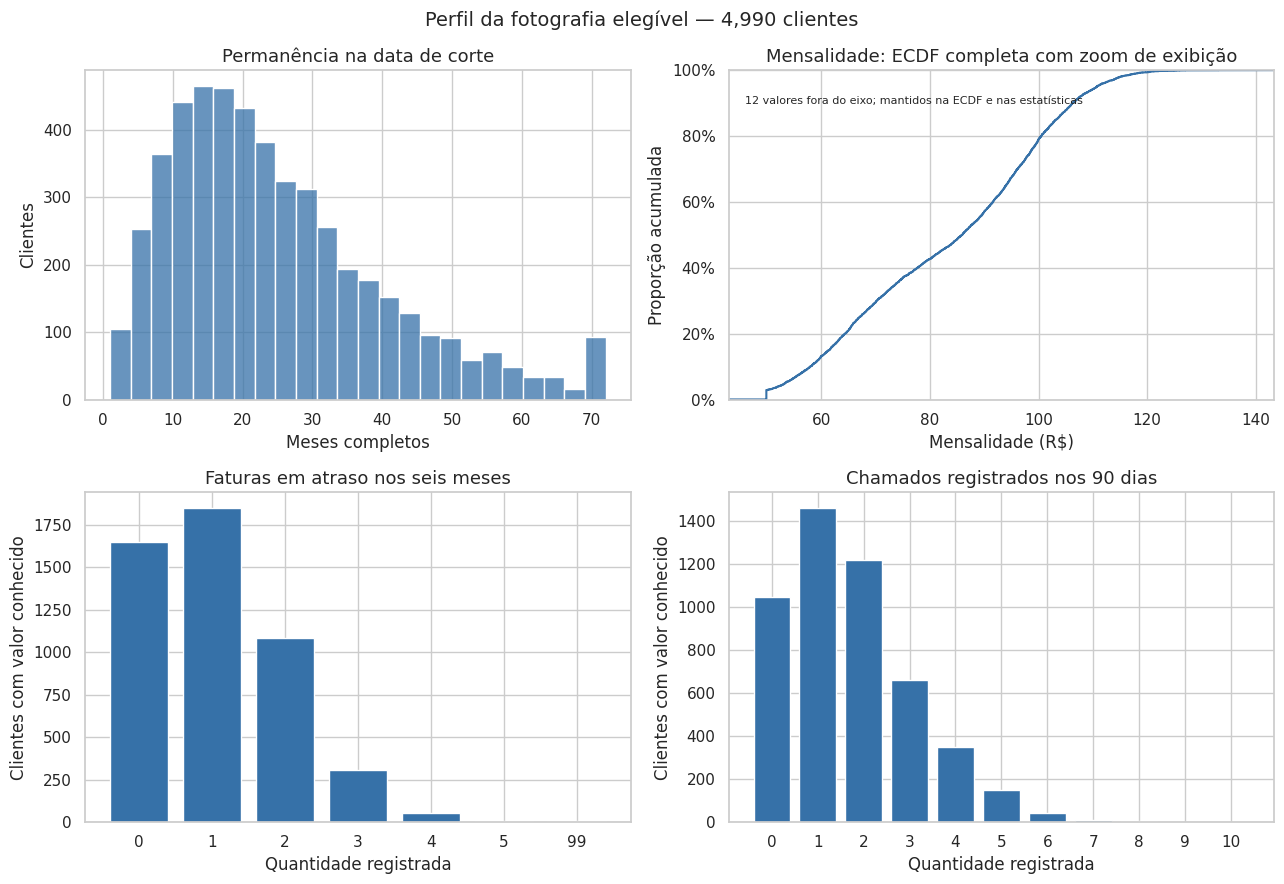

In [97]:
from matplotlib.ticker import PercentFormatter

fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(data=visao_elegivel, x="tempo_cliente_meses", bins=24, ax=eixos[0, 0], color="#3671a8")
eixos[0, 0].set(title="Permanência na data de corte", xlabel="Meses completos", ylabel="Clientes")
sns.ecdfplot(data=visao_elegivel, x="mensalidade_rs", ax=eixos[0, 1], color="#3671a8")
mensalidades_regulares = visao_elegivel.loc[visao_elegivel["mensalidade_rs"].between(10, 500), "mensalidade_rs"]
limite_baixo = float(mensalidades_regulares.min())
limite_alto = float(mensalidades_regulares.max())
margem = max((limite_alto - limite_baixo) * 0.08, 1)
eixos[0, 1].set_xlim(limite_baixo - margem, limite_alto + margem)
fora_eixo = visao_elegivel["mensalidade_rs"].notna() & ~visao_elegivel["mensalidade_rs"].between(limite_baixo - margem, limite_alto + margem)
eixos[0, 1].text(0.03, 0.92, f"{int(fora_eixo.sum())} valores fora do eixo; mantidos na ECDF e nas estatísticas", transform=eixos[0, 1].transAxes, fontsize=8, va="top")
eixos[0, 1].yaxis.set_major_formatter(PercentFormatter(1))
eixos[0, 1].set(title="Mensalidade: ECDF completa com zoom de exibição", xlabel="Mensalidade (R$)", ylabel="Proporção acumulada")
for eixo, coluna, titulo in [(eixos[1, 0], "atrasos_6m", "Faturas em atraso nos seis meses"),
                              (eixos[1, 1], "chamados_90d_registrados", "Chamados registrados nos 90 dias")]:
    contagem = visao_elegivel[coluna].value_counts().sort_index()
    eixo.bar(contagem.index.astype(int).astype(str), contagem.values, color="#3671a8")
    eixo.set(title=titulo, xlabel="Quantidade registrada", ylabel="Clientes com valor conhecido")
fig.suptitle(f"Perfil da fotografia elegível — {len(visao_elegivel):,} clientes", fontsize=14)
fig.tight_layout(); plt.show()


### 4.2. Perfil categórico

Agrupamos grafias equivalentes somente para apresentação, com os valores originais
mantidos em `fotografia`. O grupo `[sem informação]` representa ausência, sem
substituir a informação de negócio. Aqui examinamos composição; taxas de churn
serão tratadas na Parte 6 para não confundir prevalência do grupo com seu risco.


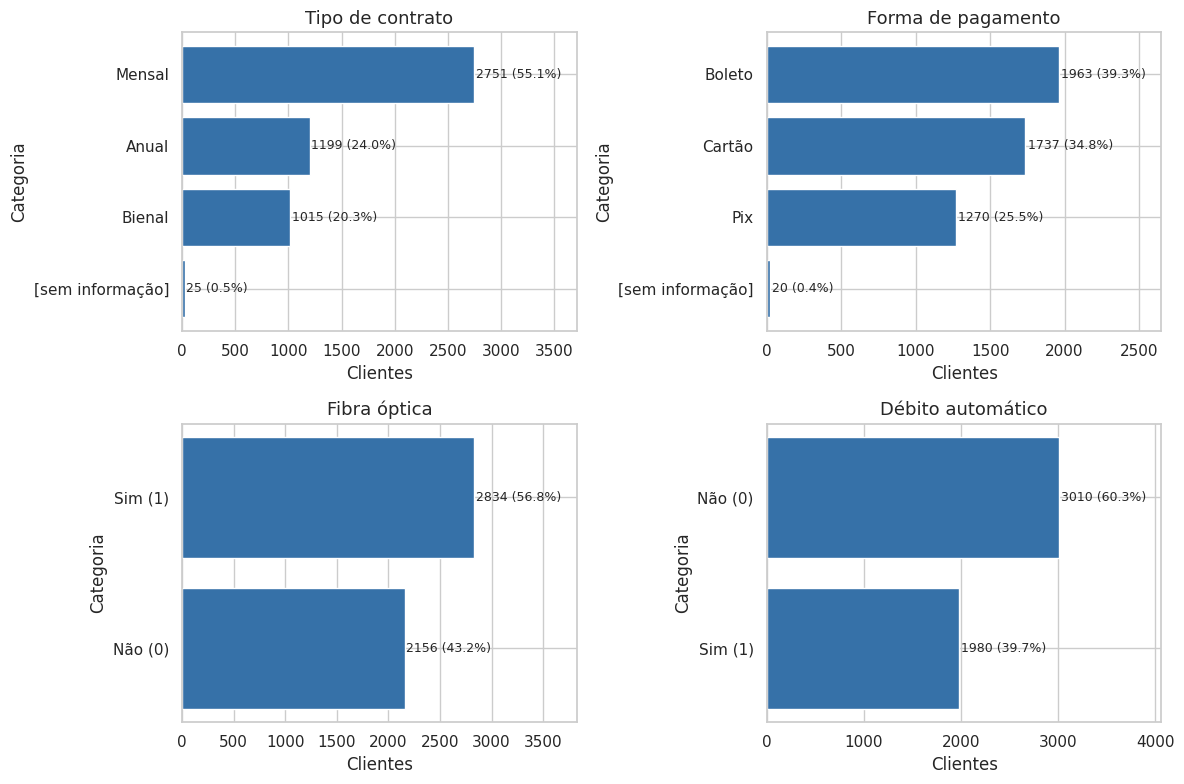

In [98]:
rotulos_categorias = {
    "tipo_contrato_grupo": "Tipo de contrato", "forma_pagamento_grupo": "Forma de pagamento",
    "fibra_optica": "Fibra óptica", "debito_automatico": "Débito automático",
}
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
for eixo, (coluna, titulo) in zip(eixos.flat, rotulos_categorias.items()):
    frequencias = visao_elegivel[coluna].value_counts(dropna=False)
    rotulos = [str(v) if coluna.endswith("_grupo") else {0: "Não (0)", 1: "Sim (1)"}.get(v, str(v)) for v in frequencias.index]
    eixo.barh(rotulos, frequencias.values, color="#3671a8")
    for i, n in enumerate(frequencias.values):
        eixo.text(n + 15, i, f"{n} ({100*n/len(visao_elegivel):.1f}%)", va="center", fontsize=9)
    eixo.set(title=titulo, xlabel="Clientes", ylabel="Categoria")
    eixo.set_xlim(0, frequencias.max() * 1.35)
    eixo.invert_yaxis()
fig.tight_layout(); plt.show()


**Achados da fotografia elegível:** a permanência mediana continua **21 meses**
(quartis 13 e 33), a mensalidade mediana **R$ 85,90** (média R$ 91,27) e a mediana
de faturas em atraso **1**. Agora as contagens conhecidas de suporte incluem os
zeros de ausência de evento: são **4.957 clientes**, com medianas de **0, 1 e 1**
nas janelas de 30/60/90 dias e médias de aproximadamente **0,58 / 1,14 / 1,71**.
Os **33 históricos inconsistentes** ficam desconhecidos nessa comparação.

Antes, excluir os vazios da descrição de suporte produzia mediana de 2 em 90 dias;
com a semântica da Aula 1, ela passa para **1**. Não é uma imputação pela média ou
mediana, mas interpretação do registro de eventos conforme a regra didática.

A regra IQR continua sinalizando **143 permanências acima de 63 meses** e **12
mensalidades**. Permanências longas dentro de 0–120 meses não são violações de
validade. Já mensalidades −85 e 9.999 violam os domínios da Aula 2, independentemente
do critério IQR. Seu efeito na média e no desvio padrão de R$ 284,77 continua presente;
o zoom dos gráficos não altera os cálculos. Composição categórica não é risco de churn.


## 5. Compreensão da variável-alvo

A comparação usa **`churn_60d`**, construído com a premissa didática de
acompanhamento completo de todos os elegíveis até 21/11/2026, confirmada pelo usuário. Assim, há
desfecho conhecido nos 60 dias para esses clientes. Maturação do histórico
permanece uma condição separada para a formação da coorte principal.

Exibimos quantidade e taxa com intervalo de Wilson de 95%, que evidencia a
incerteza de grupos pequenos. É um resumo descritivo binomial, sem estabelecer
causalidade, validade externa ou independência garantida dos registros.


,Grupo,Clientes,Desfechos observados,Churn=1,Churn=0,Taxa de churn (%),IC95 inferior (%),IC95 superior (%)
0,Principal (≥60 dias),4976,4976,1763,3213,35.43,34.11,36.77
1,Novos (<60 dias),14,14,9,5,64.29,38.76,83.66


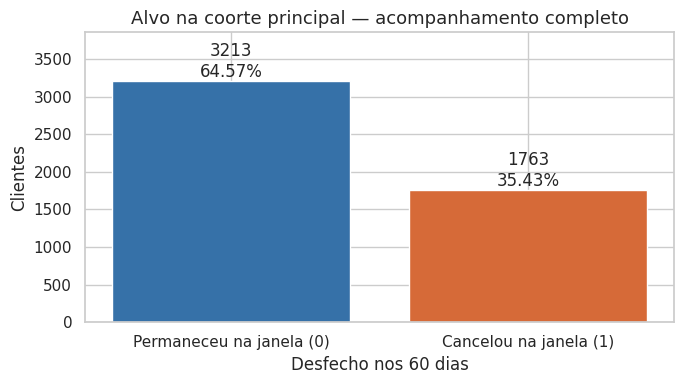

In [99]:
def resumir_taxa(dados, coluna_grupo):
    linhas = []
    for grupo, parte in dados.groupby(coluna_grupo, dropna=False, observed=True, sort=False):
        y = parte["churn_60d"].dropna().astype(int)
        n = len(y); positivos = int(y.sum())
        if n:
            taxa = positivos / n; z = 1.96
            centro = (taxa + z*z/(2*n)) / (1 + z*z/n)
            margem = z*np.sqrt(taxa*(1-taxa)/n + z*z/(4*n*n)) / (1 + z*z/n)
        else:
            taxa = centro = margem = np.nan
        linhas.append({"Grupo": str(grupo), "Clientes": len(parte), "Desfechos observados": n,
                       "Churn=1": positivos, "Churn=0": n - positivos,
                       "Taxa de churn (%)": 100*taxa, "IC95 inferior (%)": 100*(centro-margem),
                       "IC95 superior (%)": 100*(centro+margem)})
    return pd.DataFrame(linhas)

taxas_coortes = resumir_taxa(visao_elegivel, "coorte")
display(taxas_coortes.round(2))
classes_principal = amostra_principal["churn_60d"].value_counts().reindex([0, 1], fill_value=0)
fig, eixo = plt.subplots(figsize=(7, 4))
eixo.bar(["Permaneceu na janela (0)", "Cancelou na janela (1)"], classes_principal.values,
         color=["#3671a8", "#d66a38"])
for i, n in enumerate(classes_principal.values):
    eixo.text(i, n, f"{n}\n{100*n/len(amostra_principal):.2f}%", ha="center", va="bottom")
eixo.set(title="Alvo na coorte principal — acompanhamento completo", xlabel="Desfecho nos 60 dias", ylabel="Clientes")
eixo.set_ylim(0, classes_principal.max()*1.2)
fig.tight_layout(); plt.show()


**Resultado com acompanhamento completo assumido no exercício:** na coorte principal, há **1.763
cancelamentos (35,43%)** e **3.213 permanências na janela (64,57%)**. A classe
positiva é minoritária, mas não residual; isso reforça acompanhar recall e falsos
positivos em vez de avaliar futuramente apenas uma taxa global de acerto.
Nenhum balanceamento ou treinamento foi realizado.

Nos novos, há **9 cancelamentos em 14 clientes (64,29%)**, com IC95% de Wilson
aproximadamente **38,76%–83,66%**. A pequena amostra exige cautela e não sustenta,
sozinha, a criação de um modelo Early Churn confiável.

**Sob a premissa didática de cobertura completa:** todos os **4.990 elegíveis** têm desfecho conhecido:
**1.772 cancelamentos** e **3.218 permanências** no horizonte. Não há rótulos
desconhecidos entre os elegíveis. Os 10 casos com cronologia incompatível continuam
fora dessa comparação e sem alvo utilizável; não recebem classe zero.


## 6. Análise bivariada: características e churn

### 6.1. Medidas numéricas por desfecho

Usamos somente a **coorte principal maturada**. As medianas e quartis são úteis
porque os valores que violam domínios permanecem no arquivo; as médias são apresentadas
para tornar visível sua influência. `n` informa a disponibilidade de cada atributo.
As taxas e os grupos usam o desfecho conhecido com acompanhamento completo assumido no exercício.


tempo_cliente_meses               mensalidade_rs                \
                        count   mean median          count   mean median   
churn_60d                                                                  
0                        3213  27.71   24.0           3141  87.14  81.39   
1                        1763  19.46   17.0           1715  98.89  91.19   

          atrasos_6m              chamados_30d_registrados               \
               count  mean median                    count  mean median   
churn_60d                                                                 
0               3188  1.07    1.0                     3206  0.49    0.0   
1               1753  1.44    1.0                     1747  0.75    1.0   

          chamados_60d_registrados              chamados_90d_registrados  \
                             count  mean median                    count   
churn_60d                                                                  
0                             3206  0.95    1.0                     3206   
1                             1747  1.47    1.0                     1747   

                        
           mean median  
churn_60d               
0          1.43    1.0  
1          2.22    2.0

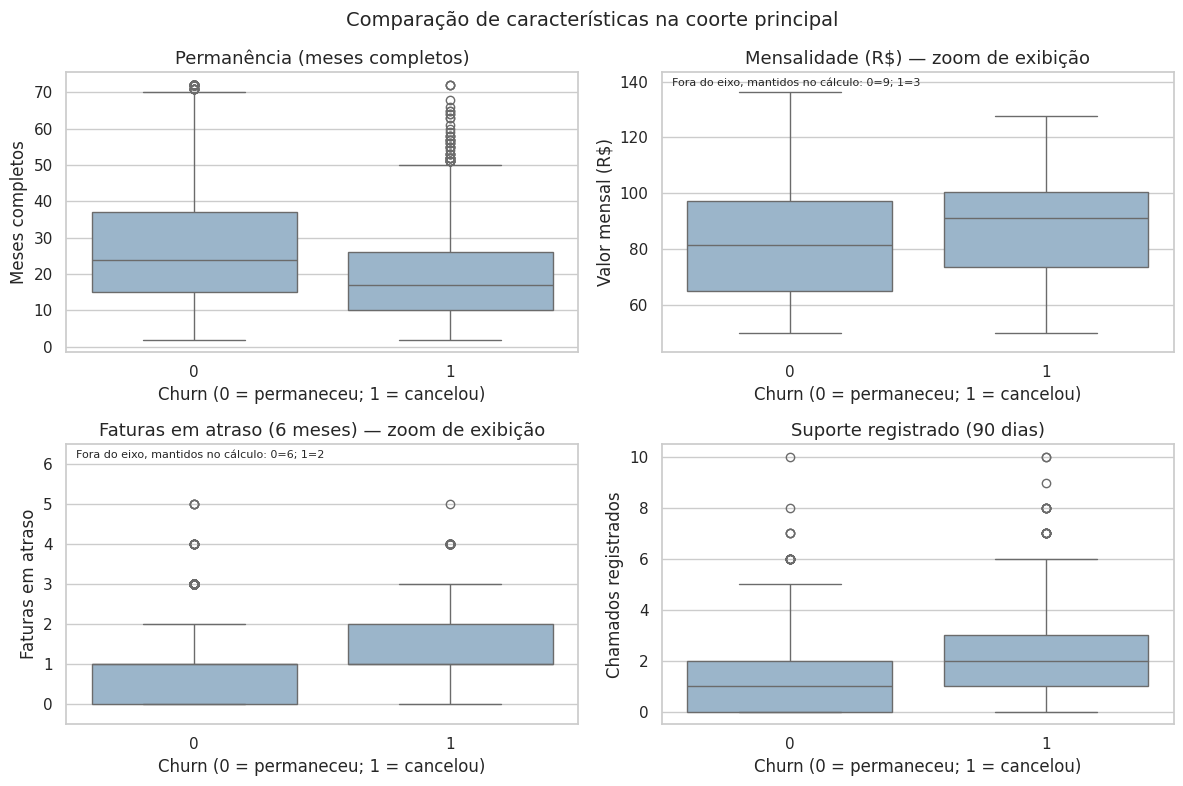

In [100]:
comparacao_numerica = amostra_principal.groupby("churn_60d")[medidas_numericas].agg(["count", "mean", "median"])
display(comparacao_numerica.round(2))
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
for eixo, coluna, titulo in zip(eixos.flat,
        ["tempo_cliente_meses", "mensalidade_rs", "atrasos_6m", "chamados_90d_registrados"],
        ["Permanência (meses completos)", "Mensalidade (R$)", "Faturas em atraso (6 meses)", "Suporte registrado (90 dias)"]):
    dados_plot = amostra_principal.loc[amostra_principal[coluna].notna(), ["churn_60d", coluna]].copy()
    dados_plot["churn_60d"] = dados_plot["churn_60d"].astype(int)
    sns.boxplot(data=dados_plot, x="churn_60d", y=coluna, order=[0, 1], color="#93b6d2", ax=eixo)
    if coluna in ["mensalidade_rs", "atrasos_6m"]:
        if coluna == "mensalidade_rs":
            minimo_plot, maximo_plot = limite_baixo - margem, limite_alto + margem
        else:
            minimo_plot, maximo_plot = -0.5, 6.5
        eixo.set_ylim(minimo_plot, maximo_plot)
        fora_plot = dados_plot.loc[~dados_plot[coluna].between(minimo_plot, maximo_plot)]
        totais_fora = fora_plot.groupby("churn_60d").size().reindex([0, 1], fill_value=0)
        eixo.text(0.02, 0.98, f"Fora do eixo, mantidos no cálculo: 0={totais_fora[0]}; 1={totais_fora[1]}",
                  transform=eixo.transAxes, va="top", fontsize=8)
        titulo += " — zoom de exibição"
    eixo.set(title=titulo, xlabel="Churn (0 = permaneceu; 1 = cancelou)", ylabel={"tempo_cliente_meses": "Meses completos", "mensalidade_rs": "Valor mensal (R$)", "atrasos_6m": "Faturas em atraso", "chamados_90d_registrados": "Chamados registrados"}[coluna])
fig.suptitle("Comparação de características na coorte principal", fontsize=14)
fig.tight_layout(); plt.show()


### 6.2. Categorias e taxas de cancelamento

Comparamos taxas dentro de cada grupo, sempre com seu denominador e intervalo
de incerteza. Isso evita concluir que um grupo tem risco alto só por conter mais
clientes. Ausências aparecem como grupo diagnóstico; não são uma nova modalidade
contratual. As associações observadas não isolam diferenças entre os demais atributos.


,Atributo,Grupo,Clientes,Desfechos observados,Churn=1,Churn=0,Taxa de churn (%),IC95 inferior (%),IC95 superior (%)
0,Tipo de contrato,Bienal,1013,1013,156,857,15.40,13.31,17.75
1,Tipo de contrato,Mensal,2741,2741,1290,1451,47.06,45.20,48.93
2,Tipo de contrato,Anual,1197,1197,306,891,25.56,23.17,28.11
3,Tipo de contrato,[sem informação],25,25,11,14,44.00,26.67,62.93
4,Forma de pagamento,Boleto,1957,1957,684,1273,34.95,32.87,37.09
5,Forma de pagamento,Cartão,1729,1729,603,1126,34.88,32.66,37.15
6,Forma de pagamento,Pix,1270,1270,466,804,36.69,34.09,39.38
7,Forma de pagamento,[sem informação],20,20,10,10,50.00,29.93,70.07
8,Fibra óptica,0,2150,2150,560,1590,26.05,24.24,27.94
9,Fibra óptica,1,2826,2826,1203,1623,42.57,40.76,44.40


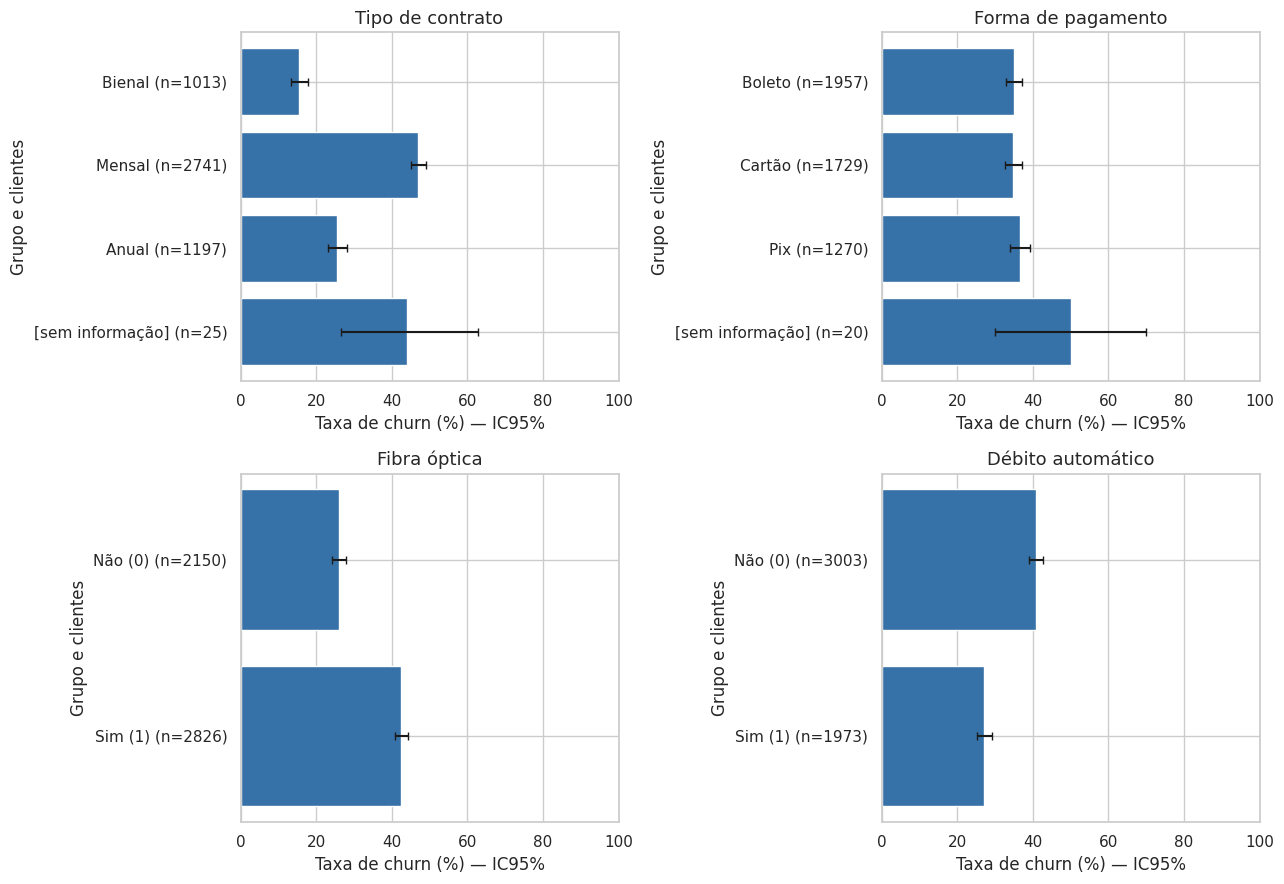

In [101]:
taxas_categorias = []
fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
for eixo, (coluna, titulo) in zip(eixos.flat, rotulos_categorias.items()):
    resumo = resumir_taxa(amostra_principal, coluna)
    resumo.insert(0, "Atributo", titulo)
    taxas_categorias.append(resumo)
    nomes_grupos = resumo["Grupo"] if coluna.endswith("_grupo") else resumo["Grupo"].map({"0": "Não (0)", "1": "Sim (1)"})
    rotulos = [f"{g} (n={n})" for g, n in zip(nomes_grupos, resumo["Clientes"])]
    taxas = resumo["Taxa de churn (%)"].to_numpy()
    erro = np.vstack([taxas - resumo["IC95 inferior (%)"].to_numpy(), resumo["IC95 superior (%)"].to_numpy() - taxas])
    eixo.barh(rotulos, taxas, xerr=erro, capsize=3, color="#3671a8")
    eixo.set(title=titulo, xlabel="Taxa de churn (%) — IC95%", ylabel="Grupo e clientes")
    eixo.set_xlim(0, 100); eixo.invert_yaxis()
tabela_taxas_categorias = pd.concat(taxas_categorias, ignore_index=True)
display(tabela_taxas_categorias.round(2))
fig.tight_layout(); plt.show()


**Associações na coorte principal:** os resultados de permanência e mensalidade
não mudaram: medianas de **17 contra 24 meses** e **R$ 91,19 contra R$ 81,39**
para cancelamento e permanência, respectivamente. A mediana de faturas em atraso
continua 1 nos dois grupos, com média sensível às violações de domínio.

Com zeros de evento e históricos comprometidos sinalizados, o suporte em 90 dias
tem mediana de **2 entre cancelamentos** e **1 entre permanências**; as médias
são **2,22 e 1,43**, respectivamente. São **1.747 contagens conhecidas entre 1.763
cancelamentos** e **3.206 entre 3.213 permanências**. Os 16 e 7 restantes têm
cronologia inconsistente. A associação é descritiva e não demonstra causalidade.

As taxas de churn permanecem **47,06% no contrato Mensal**, **25,56% no Anual** e
**15,40% no Bienal**. Com fibra, **42,57%**, contra **26,05%** sem fibra; com débito
automático, **27,12%**, contra **40,89%** sem ele. Essas comparações são marginais,
sem controlar permanência, contrato ou mensalidade. Os meios de pagamento conhecidos
continuam entre **34,88% e 36,69%**, com intervalos sobrepostos; isso não comprova
igualdade de risco. Grupos sem informação continuam pequenos e exigem cautela.


## 7. Correlações entre atributos

A matriz de **Spearman** usa postos, reduzindo a influência da magnitude dos
extremos sem apagar valores. Para obter uma matriz com o mesmo conjunto de
clientes em todas as células, usamos somente casos completos nas variáveis
selecionadas e informamos quantos ficaram fora dessa comparação. Isso não é
uma exclusão da fotografia nem imputação.

Identificadores, datas brutas e alvo ficam fora da matriz. Os indicadores 0/1
preservam sua natureza binária. Janelas cumulativas de suporte compartilham
eventos por construção; correlação entre elas não é evidência de causalidade.


Casos completos na correlação: 4798 de 4976; fora apenas desta comparação: 178


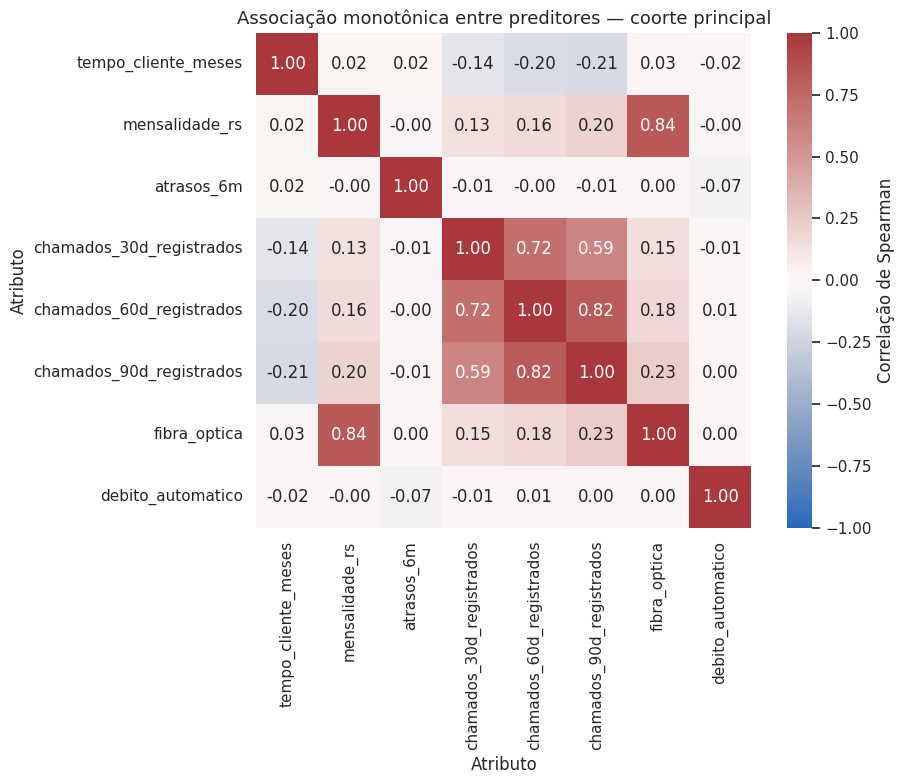

In [102]:
atributos_correlacao = medidas_numericas + ["fibra_optica", "debito_automatico"]
casos_completos = amostra_principal[atributos_correlacao].dropna().astype(float)
correlacao_spearman = casos_completos.rank(method="average").corr(method="pearson")
print(f"Casos completos na correlação: {len(casos_completos)} de {len(amostra_principal)}; fora apenas desta comparação: {len(amostra_principal)-len(casos_completos)}")
fig, eixo = plt.subplots(figsize=(10, 8))
sns.heatmap(correlacao_spearman, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, ax=eixo, cbar_kws={"label": "Correlação de Spearman"})
eixo.set(title="Associação monotônica entre preditores — coorte principal", xlabel="Atributo", ylabel="Atributo")
fig.tight_layout(); plt.show()


**Resultados recalculados:** a matriz agora usa **4.798 casos completos**, antes
3.804, de 4.976 clientes na coorte principal. A mudança vem da interpretação dos
vazios de suporte como zero e da sinalização dos históricos cronologicamente
inconsistentes como desconhecidos.

Mensalidade e fibra têm correlação de postos de aproximadamente **0,84**, antes
0,82. As correlações entre suporte de 30/60 dias e 60/90 dias passam a **0,72** e
**0,82** (antes 0,65 e 0,72). Essas janelas compartilham eventos por construção.
Permanência e suporte em 90 dias têm associação negativa fraca, de aproximadamente
**−0,21**, antes −0,19. Essas associações não são efeitos independentes nem medidas
de importância preditiva e ainda dependem do recorte de casos completos.


## 8. Investigações complementares

### 8.1. Clientes novos e impacto da maturação

A política das aulas considera **histórico ≥60 dias** no modelo principal.
Os novos são preservados, com perfil e desfecho observado analisados separadamente.
Sua janela histórica menor pode reduzir as contagens registradas de suporte;
isso não significa necessariamente menor necessidade de atendimento.
Uma alternativa futura é Early Churn, com desenho próprio e cobertura bem definida.


In [103]:
perfil_coortes = visao_elegivel.groupby("coorte", sort=False).agg(
    clientes=("id_cliente", "size"), historico_min_dias=("tempo_cliente_dias", "min"),
    historico_mediano_dias=("tempo_cliente_dias", "median"), mensalidade_mediana=("mensalidade_rs", "median"),
    atrasos_medianos=("atrasos_6m", "median"), chamados_90d_medianos=("chamados_90d_registrados", "median"),
    sem_chamados_registrados=("sem_chamados_registrados", "sum"),
    suporte_desconhecido=("chamados_90d_registrados", lambda s: int(s.isna().sum()))
)
display(perfil_coortes.round(2))
perfil_novos_categorico = pd.crosstab(clientes_novos["tipo_contrato_grupo"], clientes_novos["forma_pagamento_grupo"])
display(perfil_novos_categorico)
impacto_maturacao = pd.DataFrame([
    {"Política": "Todos os elegíveis", "Clientes": len(visao_elegivel), "Churn=1": int(visao_elegivel["churn_60d"].sum()), "Taxa de churn (%)": 100*visao_elegivel["churn_60d"].mean()},
    {"Política": "Principal: histórico ≥60 dias", "Clientes": len(amostra_principal), "Churn=1": int(amostra_principal["churn_60d"].sum()), "Taxa de churn (%)": 100*amostra_principal["churn_60d"].mean()},
    {"Política": "Novos: histórico <60 dias", "Clientes": len(clientes_novos), "Churn=1": int(clientes_novos["churn_60d"].sum()), "Taxa de churn (%)": 100*clientes_novos["churn_60d"].mean()},
])
display(impacto_maturacao.round(2))


,clientes,historico_min_dias,historico_mediano_dias,mensalidade_mediana,atrasos_medianos,chamados_90d_medianos,sem_chamados_registrados,suporte_desconhecido
coorte,,,,,,,,
Principal (≥60 dias),4976,62,639.0,85.90,1.0,1.0,1045,23
Novos (<60 dias),14,31,31.0,85.34,1.0,0.5,2,10


forma_pagamento_grupo,Boleto,Cartão
tipo_contrato_grupo,,
Anual,1,1
Bienal,0,2
Mensal,5,5


,Política,Clientes,Churn=1,Taxa de churn (%)
0,Todos os elegíveis,4990,1772,35.51
1,Principal: histórico ≥60 dias,4976,1763,35.43
2,Novos: histórico <60 dias,14,9,64.29


### 8.2. Sensibilidade a problemas de qualidade

Comparamos a coorte principal completa com dois subconjuntos diagnósticos:
clientes sem violação das faixas didáticas de mensalidade/atrasos e clientes
sem chamados anteriores à aquisição. Ausências são mantidas e contadas, não
corrigidas. Essas comparações não autorizam a exclusão de clientes nem a escolha
de regras para maximizar uma taxa; apenas mostram consequências de decisões futuras.


In [104]:
sem_violacao_dominio = ~(amostra_principal["violacao_dominio_mensalidade_rs"] | amostra_principal["violacao_dominio_atrasos_6m"])
cenarios_qualidade = {
    "Principal completa": amostra_principal,
    "Sem violação das faixas (ausências mantidas)": amostra_principal.loc[sem_violacao_dominio],
    "Sem histórico de chamados anterior à aquisição": amostra_principal.loc[~amostra_principal["inconsistencia_suporte"]],
}
sensibilidade_qualidade = pd.DataFrame([
    {"Cenário exploratório": nome, "Clientes": len(parte), "Churn=1": int(parte["churn_60d"].sum()),
     "Taxa de churn (%)": 100*parte["churn_60d"].mean(),
     "Mensalidade média (R$)": parte["mensalidade_rs"].mean(), "Mensalidade mediana (R$)": parte["mensalidade_rs"].median()}
    for nome, parte in cenarios_qualidade.items()
])
display(sensibilidade_qualidade.round(2))


,Cenário exploratório,Clientes,Churn=1,Taxa de churn (%),Mensalidade média (R$),Mensalidade mediana (R$)
0,Principal completa,4976,1763,35.43,91.29,85.90
1,Sem violação das faixas (ausências mantidas),4956,1758,35.47,83.43,85.97
2,Sem histórico de chamados anterior à aquisição,4953,1747,35.27,91.32,85.91


**Maturação:** as quantidades não mudaram: 14 novos são **0,28% dos 4.990 elegíveis**
e concentram 9 dos 1.772 cancelamentos (**0,51%**). A taxa de churn é **35,51%** em
todos os elegíveis e **35,43%** nos maturados; os novos têm taxa de **64,29%**, com
amostra pequena e intervalo amplo já apresentados na Parte 5.

A revisão de suporte deixa **23 históricos desconhecidos na coorte principal**
e **10 entre os 14 novos**, por cronologia inconsistente. Há 1.045 maturados e 2
novos sem chamados registrados, agora com zero. A mediana em 90 dias é **1 nos
maturados** e **0,5 nos novos**, mas esta última usa somente **4 contagens conhecidas**.
Não se pode generalizar esse perfil nem interpretá-lo como menor necessidade de
suporte. Além disso, os novos têm apenas 31 dias de exposição, não 60/90 dias completos.

**Sensibilidade à qualidade:** os subconjuntos continuam com **4.956 clientes** sem
violações de mensalidade/atrasos e **4.953** sem cronologia inconsistente de suporte.
No primeiro, a mensalidade média passa de **R$ 91,29 para R$ 83,43**, com mediana
próxima (R$ 85,90 para R$ 85,97) e taxa de churn de **35,47%**. No segundo, a taxa é
**35,27%**, contra 35,43% na coorte completa. Os subconjuntos se sobrepõem: não somar
suas contagens. A estabilidade de uma taxa não elimina uma violação de validade,
e não autoriza a exclusão definitiva de clientes.


## 9. Síntese e encaminhamentos

**Autoridade das decisões.** As regras conceituais e temporais das Aulas 1 e 2
do professor Germano Vasconcelos, conforme fornecidas no projeto, prevalecem
sobre exemplos genéricos de ML e sobre rótulos contraditórios de tabelas didáticas.
O conflito entre “60 dias” e 21/11 foi documentado: o alvo termina em 20/11,
enquanto a observação permanece em 21/11. Não presumimos outras divergências
nos slides sem acesso aos PDFs.

**Aprendizado supervisionado.** O alvo é cancelamento no horizonte, não existência
de qualquer data. A coorte principal exige maturação ≥60 dias; clientes novos
têm análise própria, sem exclusão definitiva. Falta de histórico anterior não é
falta de observação futura. Recall será prioritário, acompanhado de precisão,
falsos positivos, custos e capacidade operacional. Nenhum modelo foi treinado.

**Aprendizado não supervisionado.** Perfis podem ser investigados posteriormente
sem incluir o rótulo ou informações futuras. IDs, duplicação, ausências,
representações categóricas e escalas precisam de decisões coerentes com o algoritmo.

**Decisões para o pré-processamento futuro:**

| Decisão | Evidência e orientação |
|---|---|
| Consolidar por cliente e corte | Cópias idênticas foram rastreadas em uma visão auxiliar; resolver conflitos antes de materializar a base. Com múltiplos cortes, avaliar chave composta e validação temporal. |
| Documentar a premissa de cobertura futura | Acompanhamento completo até 21/11/2026 adotado didaticamente para todos os elegíveis; não é propriedade comprovada pelo CSV. Revalidar em novas bases ou cortes. |
| Definir coortes | Aplicar a maturação no desenho do modelo principal; preservar os novos e avaliar Early Churn com objetivo próprio. |
| Resolver cronologia e domínios | Investigar churn antes da aquisição, suporte incompatível e violações dos domínios da Aula 2; não substituir nem eliminar automaticamente. |
| Tratar ausências e categorias | Preservar zero de ausência de evento e NA de informação comprometida; documentar vocabulário canônico e estratégias para ausências reais. |
| Implementar atributos temporais | Manter limites, meses completos, proveniência e exposição. Documentar a semântica de eventos e as datas inválidas. Mensalidade, contrato, pagamento, atrasos e indicadores são assumidos no corte; o CSV não tem histórico de atualização para comprová-lo. |
| Prevenir vazamento | Dividir treino/teste antes de ajustar imputadores, codificadores e escalonadores; ajustar só no treino e aplicar `transform` no teste, usando pipelines. |
| Definir avaliação | Considerar corte temporal quando aplicável e sobreposição de clientes; avaliar recall com custos e falsos positivos, sem otimizar decisões nos dados de teste. |

As visões exploratórias não são uma base pronta para treinamento. A implementação
futura será modular e reproduzível, independente de execução manual deste notebook.


**Conclusão sustentada pela EDA:** há evidências de qualidade a resolver e
associações exploratórias entre o cancelamento registrado no horizonte e o perfil
contratual/financeiro. A visão principal tem 4.976 clientes; os 14 novos foram
quantificados e preservados. A proporção de churn de **35,43%** na coorte principal usa o acompanhamento
completo adotado como premissa didática, sem comprovação independente no CSV.
Os vazios de suporte representam zero eventos registrados conforme a Aula 1;
informação comprometida e violações de validade continuam sinalizadas.
Os principais achados devem orientar hipóteses e decisões futuras, sem causalidade
presumida e sem usar o teste para escolher transformações.


### 9.1. Verificação final de preservação e critérios temporais

Conferimos arquivo, DataFrame e invariantes da exploração: uma fotografia por
cliente/corte; nenhum evento futuro contado; maturação corretamente separada;
limite do alvo restrito aos 60 dias; zero de ausência de evento e NA de
informação comprometida. Os testes de borda usam a mesma função do alvo aplicada
à fotografia, com casos sintéticos identificados, sem adicionar clientes ao CSV.


In [105]:
assert FIM_HORIZONTE == pd.Timestamp("2026-11-20")
assert (DATA_OBSERVACAO - DATA_CORTE).days == 61
assert not fotografia.duplicated(["id_cliente", "data_corte"]).any()
assert pd.Series([59, 60, 61]).ge(HISTORICO_MINIMO_DIAS).tolist() == [False, True, True]
assert amostra_principal["tempo_cliente_dias"].ge(60).all()
assert clientes_novos["tempo_cliente_dias"].between(0, 59).all()
assert fotografia.loc[fotografia["sem_chamados_registrados"], "chamados_90d_registrados"].eq(0).all()
assert fotografia.loc[fotografia["inconsistencia_suporte"], "chamados_90d_registrados"].isna().all()
for dias in JANELAS_SUPORTE:
    incluido = eventos_suporte[f"incluido_{dias}d"]
    assert eventos_suporte.loc[incluido, "data"].le(DATA_CORTE).all()
    assert eventos_suporte.loc[incluido, "data"].gt(DATA_CORTE - pd.Timedelta(days=dias)).all()
    assert not eventos_suporte.loc[incluido, "antes_aquisicao"].any()
    assert eventos_suporte.loc[incluido, "cliente_representante"].all()
    assert int(incluido.sum()) == int(contagens_validas_suporte[f"chamados_{dias}d_registrados"].sum())
    bordas = pd.Series([DATA_CORTE - pd.Timedelta(days=dias), DATA_CORTE, DATA_CORTE + pd.Timedelta(days=1)])
    assert (bordas.gt(DATA_CORTE - pd.Timedelta(days=dias)) & bordas.le(DATA_CORTE)).tolist() == [False, True, False]
bordas_alvo = pd.Series([DATA_CORTE, FIM_HORIZONTE, DATA_OBSERVACAO])
assert (bordas_alvo.gt(DATA_CORTE) & bordas_alvo.le(FIM_HORIZONTE)).tolist() == [False, True, False]
if COBERTURA_GLOBAL_CONFIRMADA and horizonte_integralmente_observado:
    assert fotografia.loc[fotografia["fotografia_elegivel"], "churn_60d"].notna().all()
    assert fotografia.loc[fotografia["fotografia_elegivel"] & fotografia["cancelamento_aux"].isna(), "churn_60d"].eq(0).all()
else:
    assert fotografia.loc[fotografia["fotografia_elegivel"] & fotografia["cancelamento_aux"].isna(), "churn_60d"].isna().all()
assert fotografia.loc[~fotografia["fotografia_elegivel"], "churn_60d"].isna().all()
# Casos sintéticos de borda: testam a função usada na fotografia, sem criar clientes reais.
casos_alvo = pd.DataFrame({
    "Caso": ["No corte", "Dia seguinte ao corte", "Último dia", "Depois do horizonte",
             "Depois da observação", "Sem evento", "Data inválida", "Cliente inelegível"],
    "Cancelamento": pd.to_datetime([DATA_CORTE, DATA_CORTE + pd.Timedelta(days=1), FIM_HORIZONTE,
                                   FIM_HORIZONTE + pd.Timedelta(days=1), DATA_OBSERVACAO + pd.Timedelta(days=10),
                                   pd.NaT, pd.NaT, FIM_HORIZONTE]),
    "Elegível": [False, True, True, True, True, True, True, False],
    "Data inválida": [False, False, False, False, False, False, True, False],
})
alvo_teste = construir_churn_60d(casos_alvo["Cancelamento"], casos_alvo["Elegível"],
                               DATA_CORTE, FIM_HORIZONTE, DATA_OBSERVACAO, True, casos_alvo["Data inválida"])
esperado = pd.Series([pd.NA, 1, 1, 0, 0, 0, pd.NA, pd.NA], dtype="Int64")
pd.testing.assert_series_equal(alvo_teste, esperado)
# Mesmo um sinal de elegibilidade incorreto não pode rotular cancelamento no corte.
assert pd.isna(construir_churn_60d(pd.Series([DATA_CORTE]), pd.Series([True]),
                                 DATA_CORTE, FIM_HORIZONTE, DATA_OBSERVACAO, True).iloc[0])
sem_cobertura = construir_churn_60d(pd.Series([pd.NaT]), pd.Series([True]),
                                  DATA_CORTE, FIM_HORIZONTE, DATA_OBSERVACAO, False)
assert sem_cobertura.isna().all()
observacao_curta = construir_churn_60d(pd.Series([pd.NaT, FIM_HORIZONTE]), pd.Series([True, True]),
                                     DATA_CORTE, FIM_HORIZONTE, DATA_CORTE + pd.Timedelta(days=30), True)
assert observacao_curta.isna().all()
# Zero de evento, informação indisponível, data inválida, cronologia e perda de histórico.
zeros = pd.Series([0, 0, 0, 0, 0], dtype="Int64")
contagem_teste = consolidar_contagem_suporte(zeros, pd.Series([False, True, False, False, False]),
    pd.Series([False, False, True, False, False]), pd.Series([False, False, False, True, False]),
    pd.Series([False, False, False, False, True]))
pd.testing.assert_series_equal(contagem_teste, pd.Series([0, pd.NA, pd.NA, pd.NA, pd.NA], dtype="Int64"))
assert construir_churn_60d(casos_alvo["Cancelamento"], casos_alvo["Elegível"],
    DATA_CORTE, FIM_HORIZONTE, DATA_OBSERVACAO, True, casos_alvo["Data inválida"]).equals(alvo_teste)
print("Testes de borda do alvo, cobertura e semântica de suporte: OK.")
pd.testing.assert_frame_equal(df, pd.read_csv(caminho_base, sep=",", decimal=",", encoding="utf-8"))
assert sha256(caminho_base.read_bytes()).hexdigest() == hash_base_antes
print("EDA concluída. Arquivo e DataFrame originais preservados; nenhuma base transformada foi exportada.")
print("Critérios temporais e rastreabilidade verificados; sem modelos, pré-processamento definitivo ou commits.")


Testes de borda do alvo, cobertura e semântica de suporte: OK.
EDA concluída. Arquivo e DataFrame originais preservados; nenhuma base transformada foi exportada.
Critérios temporais e rastreabilidade verificados; sem modelos, pré-processamento definitivo ou commits.
